# TTC Ridership Analysis

This project explores Toronto Transit Commission ridership trends,
seasonal patterns, and recovery compared with 2019.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Resolve the data file relative to this notebook, tolerating a kernel started
# from the repo root (one level up) instead of from this folder.
DATA_FILE = Path("Data_source") / "TorontoMeasureData.csv"
data_path = next(
    (p / DATA_FILE for p in (Path.cwd(), Path.cwd() / "TTC") if (p / DATA_FILE).exists()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        f"{DATA_FILE} not found from {Path.cwd()} - see README 'Verify the data'"
    )

df = pd.read_csv(data_path)
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns")

df.head()

Loaded 508 rows x 4 columns


,Measure Name,Year,Period,Value
0,TTC Average Weekday Ridership,2007,Jan,1400000
1,TTC Average Weekday Ridership,2007,Feb,1486000
2,TTC Average Weekday Ridership,2007,Mar,1485000
3,TTC Average Weekday Ridership,2007,Apr,1491000
4,TTC Average Weekday Ridership,2007,May,1474000


In [2]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

df.info()

Rows: 508
Columns: 4
<class 'pandas.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Measure Name  508 non-null    str  
 1   Year          508 non-null    int64
 2   Period        462 non-null    str  
 3   Value         508 non-null    int64
dtypes: int64(2), str(2)
memory usage: 16.0 KB


## 🧹 Section 1 — Normalise & shape

Two of the four measures are monthly and two are annual, and they are published on different scales: monthly figures are **raw rides**, annual figures are in **thousands**. This section puts every observation on one schema so the rest of the notebook can join, aggregate and plot without special cases.


### 1.1 Build a tidy analysis frame

The raw export is close to tidy already, but three things would quietly corrupt any
downstream chart if left alone:

1. the two annual measures are published in **thousands**, the monthly ones in **raw rides**;
2. `Period` is null for the annual measures - those 46 nulls are structural, not missing data;
3. `Period` is a plain string, so it sorts alphabetically (Apr, Aug, Dec, ...).

This cell fixes all three and keeps the measurement basis explicit in a `unit` column,
so nothing later can accidentally sum an average into a total.


In [3]:
# --- Section 1.1 - normalise the export into one typed analysis frame ---

MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
MONTH_NUM = {name: i for i, name in enumerate(MONTH_ORDER, start=1)}

WEEKDAY = "TTC Average Weekday Ridership"
MONTHLY = "TTC Monthly Ridership"
PEAK    = "TTC Annual Passenger Rides Peak (000s)"
NONPEAK = "TTC Annual Passenger Rides Non-Peak (000s)"

MONTHLY_MEASURES = [WEEKDAY, MONTHLY]
ANNUAL_MEASURES  = [PEAK, NONPEAK]

# 1) snake_case names; a null Period is exactly what marks an annual observation
clean = (
    df.rename(columns={"Measure Name": "measure", "Year": "year",
                       "Period": "period", "Value": "raw_value"})
      .assign(granularity=lambda d: np.where(d["period"].isna(), "annual", "monthly"))
)

# 2) month number + a real datetime index - monthly observations only
clean["month"] = clean["period"].map(MONTH_NUM).astype("Int8")

clean["date"] = pd.NaT
is_monthly = clean["month"].notna()
clean.loc[is_monthly, "date"] = pd.to_datetime(
    {"year":  clean.loc[is_monthly, "year"],
     "month": clean.loc[is_monthly, "month"].astype("int64"),
     "day":   1}
).to_numpy()

# 3) make the measurement basis explicit: can this number be summed?
clean["unit"] = clean["measure"].map(
    {WEEKDAY: "avg_weekday", MONTHLY: "total", PEAK: "total", NONPEAK: "total"}
)

# 4) annual measures are published in THOUSANDS -> rescale so every value is whole rides
clean["value"] = np.where(
    clean["granularity"] == "annual", clean["raw_value"] * 1000, clean["raw_value"]
).astype("int64")

# 5) flag the incomplete final year, derived from the data rather than hardcoded
PARTIAL_YEAR = int(clean.loc[is_monthly, "year"].max())
clean["is_partial_year"] = clean["year"] == PARTIAL_YEAR

# 6) ordered categoricals so month order is never alphabetical
clean = clean.assign(
    measure=pd.Categorical(clean["measure"],
                           categories=[WEEKDAY, MONTHLY, PEAK, NONPEAK], ordered=True),
    granularity=pd.Categorical(clean["granularity"],
                               categories=["monthly", "annual"], ordered=True),
    unit=pd.Categorical(clean["unit"], categories=["total", "avg_weekday"], ordered=True),
    period=pd.Categorical(clean["period"], categories=MONTH_ORDER, ordered=True),
    year=clean["year"].astype("int16"),
)[["measure", "granularity", "unit", "year",
   "period", "month", "date", "value", "is_partial_year"]]

print(f"clean: {clean.shape[0]:,} rows x {clean.shape[1]} columns")
print(f"       measures     {list(clean['measure'].cat.categories)}")
print(f"       partial year {PARTIAL_YEAR}")
print(f"       dtypes       {', '.join(f'{c}={t}' for c, t in clean.dtypes.astype(str).items())}")
clean.head()

clean: 508 rows x 9 columns
       measures     ['TTC Average Weekday Ridership', 'TTC Monthly Ridership', 'TTC Annual Passenger Rides Peak (000s)', 'TTC Annual Passenger Rides Non-Peak (000s)']
       partial year 2026
       dtypes       measure=category, granularity=category, unit=category, year=int16, period=category, month=Int8, date=datetime64[ns], value=int64, is_partial_year=bool


,measure,granularity,unit,year,period,month,date,value,is_partial_year
0,TTC Average Weekday Ridership,monthly,avg_weekday,2007,Jan,1,2007-01-01,1400000,False
1,TTC Average Weekday Ridership,monthly,avg_weekday,2007,Feb,2,2007-02-01,1486000,False
2,TTC Average Weekday Ridership,monthly,avg_weekday,2007,Mar,3,2007-03-01,1485000,False
3,TTC Average Weekday Ridership,monthly,avg_weekday,2007,Apr,4,2007-04-01,1491000,False
4,TTC Average Weekday Ridership,monthly,avg_weekday,2007,May,5,2007-05-01,1474000,False


### 1.2 Assert the profile (the README, executable)

Every data-quality claim in the README is checked here, so a refreshed upstream file
fails loudly instead of silently changing the story. The reconciliation assert is the
important one: it proves the `x1000` unit conversion is right, because the annual
peak + non-peak totals then reproduce the summed monthly ridership to within rounding.


In [4]:
# --- Section 1.2 - every README data-quality claim, checked in code ---

assert clean.shape == (508, 9), clean.shape
assert clean["value"].notna().all() and (clean["value"] > 0).all(), "null or zero rides"
assert not clean.duplicated(["measure", "year", "month"]).any(), "duplicate keys"

# 237 / 225 monthly, 23 / 23 annual (counts follow the categorical order above)
assert clean["measure"].value_counts(sort=False).tolist() == [237, 225, 23, 23], \
    clean["measure"].value_counts(sort=False).to_dict()
assert clean["granularity"].value_counts().sort_index().to_dict() == \
    {"annual": 46, "monthly": 462}

# the 46 nulls are structural: only the annual measures lack a month
assert clean["period"].isna().sum() == 46
assert clean.loc[clean["period"].isna(), "granularity"].eq("annual").all()
assert clean["month"].isna().sum() == 46 and clean["date"].isna().sum() == 46

# every month 1-12 present, no stray label
assert sorted(clean["month"].dropna().unique().tolist()) == list(range(1, 13))

# the final year is partial and holds Jan-Sep only (9 months x 2 monthly measures)
assert PARTIAL_YEAR == 2026
assert list(clean.loc[clean["is_partial_year"], "period"].unique()) == MONTH_ORDER[:9]
assert clean["is_partial_year"].sum() == 18

# per-measure coverage matches the documented windows
coverage = clean.groupby("measure", observed=True)["year"].agg(["min", "max"])
assert coverage.loc[WEEKDAY].tolist() == [2007, 2026]
assert coverage.loc[MONTHLY].tolist() == [2008, 2026]
assert coverage.loc[PEAK].tolist()    == [2003, 2025]
assert coverage.loc[NONPEAK].tolist() == [2003, 2025]

# --- the x1000 conversion is correct: annual peak+non-peak == summed monthly ---
monthly_sum = clean.query("measure == @MONTHLY").groupby("year")["value"].sum()
annual_sum  = clean.query("measure in @ANNUAL_MEASURES").groupby("year")["value"].sum()
recon = (annual_sum / monthly_sum).dropna()          # only the 2008-2025 overlap
assert (recon - 1).abs().max() <= 2e-4, (recon - 1).abs().max()

# --- headline numbers Sections 2-7 depend on ---
total = clean.query("measure == @MONTHLY").groupby("year")["value"].sum()
assert total[2019] == 525_470_000
assert abs(total[2020] / total[2019] - 1 - (-0.5720)) < 1e-3
assert total.idxmin() == 2021 and total[2021] == 197_841_000
assert abs(total[2025] / total[2019] - 1 - (-0.2141)) < 1e-3

peak  = clean.query("measure == @PEAK").set_index("year")["value"]
nonpk = clean.query("measure == @NONPEAK").set_index("year")["value"]
share = peak / (peak + nonpk)
assert abs(share[2003] - 0.4725) < 1e-4
assert abs(share[2025] - 0.4200) < 1e-4

print(f"validated {len(clean):,} rows | unit reconciliation error "
      f"{(recon - 1).abs().max():.6%} | peak share {share[2003]:.2%} (2003) "
      f"-> {share[2025]:.2%} (2025)")
coverage

validated 508 rows | unit reconciliation error 0.010893% | peak share 47.25% (2003) -> 42.00% (2025)


,min,max
measure,,
TTC Average Weekday Ridership,2007,2026
TTC Monthly Ridership,2008,2026
TTC Annual Passenger Rides Peak (000s),2003,2025
TTC Annual Passenger Rides Non-Peak (000s),2003,2025


### 1.3 Inferring the 4-4-5 reporting periods

The monthly figures behave as though they are reported on **4-4-5 financial periods** rather
than calendar months: eight 4-week blocks plus four 5-week blocks, so `8 x 28 + 4 x 35 = 364`
days = 52 weeks per year. If that is right, it explains why a naive month-over-month change
shows a fake `+25%` every few months, and why dividing by calendar days would overstate the
long periods.

**This is an inference, not a documented fact.** The dataset's published metadata — notes,
limitations, collection method and resource descriptions — says nothing about reporting periods
or how a "month" is defined (checked against the CKAN package record, 2026-11-05). What follows
is therefore internal evidence: two columns in this extract imply the same period lengths, and
the implied lengths fall into two clean groups. That is consistent with a 4-4-5 calendar, but it
does not prove one — a different reporting mechanism could produce a similar pattern.

The table below is entered by hand and is therefore a **modelling assumption**. Everything built
on it (rides per reporting day, the seasonality index, the implied weekend estimates in Section 6)
should be read as "adjusted under an assumed 4-4-5 calendar", and confirmed against TTC
documentation before being treated as established.


In [5]:
# --- Section 1.3 - infer the 4-4-5 periodisation behind the monthly series ---

# INFERRED, NOT DOCUMENTED. The upstream metadata says nothing about reporting periods, so
# this table is a hand-entered modelling assumption. It encodes what the data implies:
# eight 4-week periods + four 5-week periods = 8*28 + 4*35 = 364 days (52 weeks) per year,
# with Mar and Jun 5-week in every year and the other two slots rotating. The checks below
# test internal consistency, not provenance: they cannot show that these were TTC's actual
# reporting periods, only that the table reproduces the observed pattern.
FIVE_WEEK_MONTHS = {
    2008: ("Jan", "Mar", "Jun", "Sep"), 2009: ("Mar", "Jun", "Sep", "Dec"),
    2010: ("Mar", "Jun", "Sep", "Dec"), 2011: ("Mar", "Jun", "Sep", "Dec"),
    2012: ("Mar", "Jun", "Sep", "Dec"), 2013: ("Jan", "Mar", "Jun", "Sep"),
    2014: ("Jan", "Mar", "Jun", "Sep"), 2015: ("Mar", "Jun", "Sep", "Dec"),
    2016: ("Mar", "Jun", "Sep", "Dec"), 2017: ("Mar", "Jun", "Sep", "Dec"),
    2018: ("Jan", "Mar", "Jun", "Nov"), 2019: ("Jan", "Mar", "Jun", "Sep"),
    2020: ("Mar", "Jun", "Sep", "Dec"), 2021: ("Mar", "Jun", "Sep", "Dec"),
    2022: ("Mar", "Jun", "Sep", "Dec"), 2023: ("Mar", "Jun", "Sep", "Dec"),
    2024: ("Mar", "Jun", "Sep", "Dec"), 2025: ("Mar", "Jun", "Sep", "Dec"),
    2026: ("Mar", "Jun", "Sep"),          # partial year: Jan-Sep only
}

periods = (
    clean.query("measure == @MONTHLY")[["year", "period", "month", "value"]]
         .rename(columns={"value": "monthly_rides"})
         .merge(clean.query("measure == @WEEKDAY")[["year", "period", "value"]]
                     .rename(columns={"value": "avg_weekday"}),
                on=["year", "period"], how="left", validate="one_to_one")
)

# weekday-equivalent days: ~24.3 for a 4-week period, ~30.1 for a 5-week one
periods["implied_days"] = (periods["monthly_rides"] / periods["avg_weekday"]).round(2)

periods["period_weeks"] = [
    5 if per in FIVE_WEEK_MONTHS[int(yr)] else 4
    for yr, per in zip(periods["year"], periods["period"])
]
periods["period_days"] = periods["period_weeks"] * 7
periods["date"] = pd.to_datetime(
    dict(year=periods["year"], month=periods["month"].astype("int64"), day=1)
).astype("datetime64[ns]")

# --- 1.3 checks: the recovered periodisation must be self-consistent ---
assert len(periods) == 225, len(periods)
assert periods["implied_days"].notna().all()
assert not periods.duplicated(["year", "period"]).any()

# the invariant: Mar and Jun are 5-week in every year, without exception
assert periods.query("period in ('Mar', 'Jun')")["period_weeks"].eq(5).all()

# exactly four 5-week periods per complete year => 364 reporting days
days_per_year = periods.groupby("year")["period_days"].sum()
five_per_year = periods.groupby("year")["period_weeks"].apply(lambda s: int(s.eq(5).sum()))
assert days_per_year.loc[2008:2025].eq(364).all(), days_per_year
assert five_per_year.loc[2008:2025].eq(4).all(), five_per_year
assert days_per_year[2026] == 273, days_per_year[2026]   # Jan-Sep: 6 * 28 + 3 * 35
assert five_per_year[2026] == 3

# the two regimes separate cleanly, so the table is not fitted to noise.
# 2020-2022 excluded: the demand collapse breaks the weekday/weekend mix.
calm = periods[~periods["year"].isin([2020, 2021, 2022])]
median_5 = calm.loc[calm["period_weeks"].eq(5), "implied_days"].median()
median_4 = calm.loc[calm["period_weeks"].eq(4), "implied_days"].median()
assert median_5 > 29 and median_4 < 26 and (median_5 - median_4) > 4, (median_4, median_5)

print("periodisation INFERRED from the data (not documented upstream):")
for weeks, label in ((4, "4-week"), (5, "5-week")):
    sub = calm.loc[calm["period_weeks"].eq(weeks), "implied_days"]
    print(f"  {label}: median {sub.median():5.2f} weekday-equivalent days "
          f"| {len(sub):3d} observations | range {sub.min():.1f}-{sub.max():.1f}")
print(f"  separation between regimes: {median_5 - median_4:.2f} days")
print("  note: consistent with a 4-4-5 calendar; confirms internal consistency, not provenance")
print(f"  reporting days per year: 364 for 2008-2025, {days_per_year[2026]} for 2026 (partial)")
print(f"  five-week periods per year: 4 for 2008-2025, {five_per_year[2026]} in 2026 (Jan-Sep only)")
periods.head()

periodisation INFERRED from the data (not documented upstream):
  4-week: median 24.34 weekday-equivalent days | 126 observations | range 20.4-27.4
  5-week: median 30.26 weekday-equivalent days |  63 observations | range 27.6-38.4
  separation between regimes: 5.92 days
  note: consistent with a 4-4-5 calendar; confirms internal consistency, not provenance
  reporting days per year: 364 for 2008-2025, 273 for 2026 (partial)
  five-week periods per year: 4 for 2008-2025, 3 in 2026 (Jan-Sep only)


,year,period,month,monthly_rides,avg_weekday,implied_days,period_weeks,period_days,date
0,2008,Jan,1,39242000,1379000,28.46,5,35,2008-01-01
1,2008,Feb,2,35150000,1476000,23.81,4,28,2008-02-01
2,2008,Mar,3,44924000,1519000,29.57,5,35,2008-03-01
3,2008,Apr,4,33965000,1446000,23.49,4,28,2008-04-01
4,2008,May,5,35357000,1479000,23.91,4,28,2008-05-01


### 1.4 Analysis frames

Everything from Section 2 onward works off three objects instead of re-querying `clean`:

- `monthly` - one row per reporting month (index = month start), carrying the daily rate
  and a 12-month rolling total
- `annual` - one row per year, with the derived peak-hour share
- `ytd(year)` - year-to-date ridership, so 2026 is never compared against a full year

The rolling 12-month total is the one place a partial year can be used honestly: a
trailing window ending in September 2026 spans twelve complete monthly observations,
so it needs no masking.


In [6]:
# --- Section 1.4 - the analysis frames every later section consumes ---

# monthly: one row per reporting period, indexed by month start
monthly = (
    clean.query("measure == @MONTHLY")
         .set_index("date")[["value", "is_partial_year"]]
         .rename(columns={"value": "ridership"})
)
monthly["avg_weekday"] = clean.query("measure == @WEEKDAY").set_index("date")["value"]
monthly = monthly.join(periods.set_index("date")[["period_weeks", "period_days"]])
monthly["rides_per_day"] = (monthly["ridership"] / monthly["period_days"]).round().astype("Int64")

# the 4-4-5 artefact is a sawtooth on the raw series; a trailing 12-month sum removes it
# without dropping any data - and stays valid through the partial final year
monthly["trailing_12m"] = monthly["ridership"].rolling(12, min_periods=12).sum().astype("Int64")

monthly.index.name = "month"
monthly = monthly[["ridership", "avg_weekday", "period_weeks", "period_days",
                   "rides_per_day", "trailing_12m", "is_partial_year"]]

# annual: peak and non-peak are separate published measures; total and share are derived
annual = pd.concat([
    clean.query("measure == @PEAK").set_index("year")["value"].rename("peak"),
    clean.query("measure == @NONPEAK").set_index("year")["value"].rename("non_peak"),
], axis=1)
annual["total"] = annual["peak"] + annual["non_peak"]
annual["peak_share"] = annual["peak"] / annual["total"]
annual.index.name = "year"


def ytd(year, through=None):
    """Ridership from January to `through` (month name), or to the last month on record."""
    frame = monthly.loc[str(year)]
    if through is not None:
        frame = frame[frame.index.month <= MONTH_NUM[through]]
    return int(frame["ridership"].sum())


# --- 1.4 checks ---
assert len(monthly) == 225
assert monthly["ridership"].notna().all() and monthly["rides_per_day"].notna().all()

# the index must be gap-free: rolling windows and pct_change() depend on it
stamp = pd.Series(monthly.index.year * 12 + monthly.index.month, index=monthly.index)
assert stamp.diff().dropna().eq(1).all(), "monthly index has a gap"
assert (stamp.iloc[0], monthly.index[-1].strftime("%Y-%m")) == (2008 * 12 + 1, "2026-09")

# annual frame: complete years only, and the derived columns are consistent
assert len(annual) == 23 and annual.index.min() == 2003 and annual.index.max() == 2025
assert annual["total"].notna().all()
assert (annual["peak"].lt(annual["total"])).all()
assert annual["peak_share"].between(0.39, 0.48).all()

# annual totals still reconcile to the monthly sums (both units are whole rides now)
monthly_year = monthly.groupby(monthly.index.year)["ridership"].sum()
overlap = annual.loc[2008:2025, "total"] / monthly_year
assert (overlap - 1).abs().max() <= 2e-4, (overlap - 1).abs().max()

# trailing window sanity: 12 observations, no partial-year distortion
assert monthly["trailing_12m"].notna().sum() == len(monthly) - 11
assert monthly["trailing_12m"].iloc[-1] == monthly["ridership"].iloc[-12:].sum()
assert int(monthly["trailing_12m"].iloc[-1]) == 409_975_000

# year-to-date helper: the only honest way to compare 2026
assert ytd(2026) == 303_355_000
assert ytd(2025, through="Sep") == 306_494_000
assert abs(ytd(2026) / ytd(2025, through="Sep") - 1 + 0.0102) < 5e-4

print(f"monthly : {monthly.shape[0]} rows x {monthly.shape[1]} cols "
      f"({monthly.index[0]:%Y-%m} to {monthly.index[-1]:%Y-%m})")
print(f"annual  : {annual.shape[0]} rows x {annual.shape[1]} cols "
      f"({annual.index.min()}-{annual.index.max()})")
print(f"trailing 12 months to {monthly.index[-1]:%b %Y}: "
      f"{monthly['trailing_12m'].iloc[-1]:,.0f} rides")
print(f"2026 YTD (Jan-Sep) {ytd(2026):,} vs 2025 YTD {ytd(2025, through='Sep'):,} "
      f"= {(ytd(2026) / ytd(2025, through='Sep') - 1) * 100:+.2f}%")
print(f"peak-hour share: {annual['peak_share'].iloc[0]:.2%} ({annual.index[0]}) "
      f"-> {annual['peak_share'].iloc[-1]:.2%} ({annual.index[-1]})")
monthly.head()

monthly : 225 rows x 7 cols (2008-01 to 2026-09)
annual  : 23 rows x 4 cols (2003-2025)
trailing 12 months to Sep 2026: 409,975,000 rides
2026 YTD (Jan-Sep) 303,355,000 vs 2025 YTD 306,494,000 = -1.02%
peak-hour share: 47.25% (2003) -> 42.00% (2025)


,ridership,avg_weekday,period_weeks,period_days,rides_per_day,trailing_12m,is_partial_year
month,,,,,,,
2008-01-01,39242000,1379000,5,35,1121200,<NA>,False
2008-02-01,35150000,1476000,4,28,1255357,<NA>,False
2008-03-01,44924000,1519000,5,35,1283543,<NA>,False
2008-04-01,33965000,1446000,4,28,1213036,<NA>,False
2008-05-01,35357000,1479000,4,28,1262750,<NA>,False


## 📈 Section 2 — Growth to 2016, then a plateau, then a collapse

Ridership grew 33% between 2003 and its high point, but the shape is not the simple
"growth until the pandemic" story it is usually told as: the peak was **2016**, and the
three years before COVID were already flat to falling. Then half the system disappeared in
a single year.

This section establishes that arc on the annual series, then decomposes it: absolute level,
peak vs non-peak composition, and the rate of change year over year.

Two framing choices matter for everything that follows:

- **calendar-year totals** stop at 2025, because the annual measures have no 2026 row;
- **a trailing 12-month sum** is used to carry the series into September 2026. Twelve
  reporting periods are 364 days regardless of where the 4-4-5 boundaries fall, so the
  window is directly comparable across eras and is not distorted by the partial year.


### 2.1 Chart style and figure export

One palette, one `save_fig()` helper, used by every figure in the notebook. Colours are
named by role rather than by hue so later sections stay visually consistent: `RED` for
ridership, `BLUE` for non-peak and comparative series, `AMBER` for the recovery era, `GREY`
for annotation furniture.

Each figure is written to `visualizations/` at 150 dpi with the data attribution baked in,
so the PNG files in the repo are the same ones the notebook displays.


In [7]:
# --- Section 2.1 - one chart style for the whole notebook ---
import matplotlib.pyplot as plt

FIG_DIR = data_path.parent.parent / "visualizations"   # .../TTC/visualizations
FIG_DIR.mkdir(exist_ok=True)

INK   = "#12232E"
RED   = "#DA291C"   # TTC red - total ridership
BLUE  = "#1F6F8B"   # non-peak rides / comparative series
AMBER = "#E9A13B"   # recovery era
GREY  = "#78868C"
LIGHT = "#DDE4E7"

CREDIT = ("Source: City of Toronto Open Data \u2014 Toronto's Dashboard Key Indicators "
          "(Open Government Licence \u2013 Toronto)")

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": LIGHT,
    "axes.labelcolor": INK,
    "axes.titlecolor": INK,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": LIGHT,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "font.size": 10,
})


def save_fig(fig, name):
    """Write a figure into visualizations/ with the data credit, and report its size."""
    fig.text(0.5, -0.055, CREDIT, ha="center", va="top", fontsize=7, color=GREY)
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print(f"saved visualizations/{path.name}  ({path.stat().st_size / 1024:.0f} KB)")
    return path


assert FIG_DIR.is_dir(), FIG_DIR
print(f"figures -> {FIG_DIR.relative_to(FIG_DIR.parent)}/  |  "
      f"matplotlib {plt.matplotlib.__version__}")

figures -> visualizations/  |  matplotlib 3.11.2


### 2.2 Annual ridership, and the trailing 12-month series

The red line is the calendar-year total. It stops at 2025 because the annual measures have no
2026 row — so the blue dashed line carries the story forward: a trailing 12-month sum, which
is 364 reporting days at every point and therefore comparable across eras.

Two things the chart shows that the usual "growth until COVID" framing misses:

- the peak was **2016** (538.1M), not 2019. Ridership fell in three of the four years to 2018
  and had only clawed back to 525.5M — still 2.3% below 2016 — when the pandemic hit.
- the **strongest 12-month stretch on record is not a calendar year** either: the window
  ending February 2018 totalled 541.3M rides, because it combines a strong 2017 second half
  with a strong 2018 first half (271.6M) before the 2018 second half dropped away.


saved visualizations/02_annual_ridership.png  (130 KB)


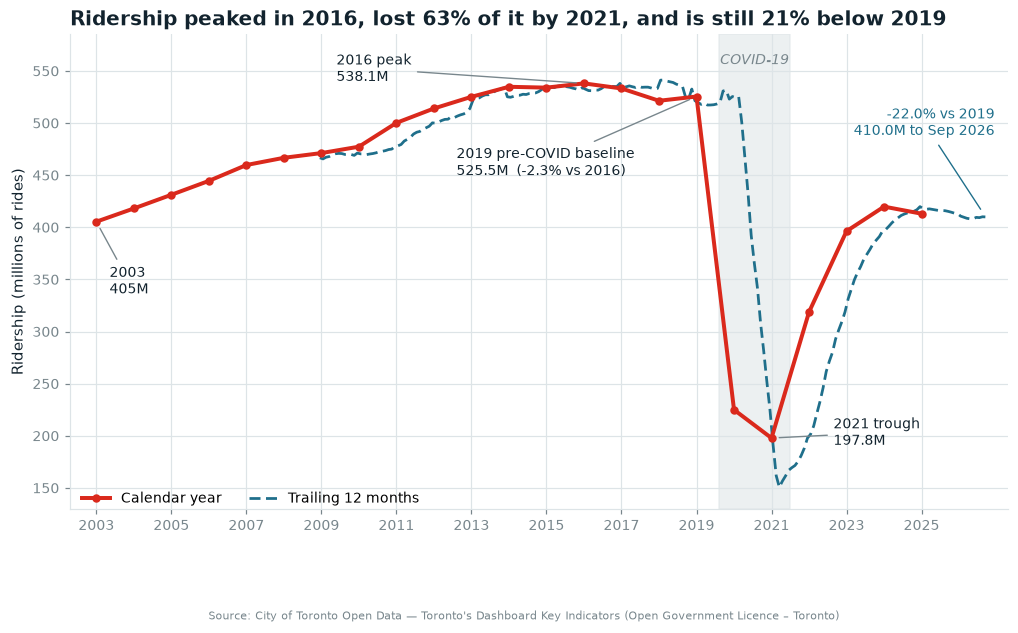

peak 2016 538.1M | 2019 525.5M (-2.3% vs peak) | trough 2021 197.8M (-63.2% vs peak) | strongest 12m 541.3M to Feb 2018


In [8]:
# --- Section 2.2 - annual ridership with a trailing 12-month overlay ---
fig, ax = plt.subplots(figsize=(11, 5.6))

years = annual.index.to_numpy()
total_m = annual["total"] / 1e6
t12_m = monthly["trailing_12m"].dropna() / 1e6
# the annual series is plotted on numeric years, so the monthly trailing window must be too -
# handing matplotlib a DatetimeIndex here would silently switch the axis to date units
t12_x = t12_m.index.year.to_numpy() + (t12_m.index.month.to_numpy() - 0.5) / 12

ax.plot(years, total_m, color=RED, lw=2.6, marker="o", ms=4.5, zorder=3,
        label="Calendar year")
ax.plot(t12_x, t12_m, color=BLUE, lw=1.8, ls=(0, (4, 2)), zorder=2,
        label="Trailing 12 months")

ax.axvspan(2019.6, 2021.5, color=LIGHT, alpha=0.55, zorder=0)
ax.text(2020.55, 560, "COVID-19", color=GREY, fontsize=9, ha="center",
        va="center", style="italic", zorder=4)


def tag(year, text, xytext):
    ax.annotate(text, xy=(year, total_m.loc[year]), xytext=xytext, fontsize=9,
                color=INK, ha="left", va="center", zorder=5,
                arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9,
                                shrinkA=2, shrinkB=5))


peak_year = int(total_m.idxmax())
tag(2003, f"2003\n{total_m.loc[2003]:.0f}M", (2003.35, 348))
tag(peak_year, f"{peak_year} peak\n{total_m.loc[peak_year]:.1f}M",
    (peak_year - 6.6, 552))
tag(2019, f"2019 pre-COVID baseline\n{total_m.loc[2019]:.1f}M  "
          f"({(total_m.loc[2019] / total_m.loc[peak_year] - 1) * 100:+.1f}% vs {peak_year})",
    (2012.6, 462))
tag(2021, f"2021 trough\n{total_m.loc[2021]:.1f}M", (2022.65, 203))

ax.annotate(f"{(t12_m.iloc[-1] / total_m.loc[2019] - 1) * 100:+.1f}% vs 2019\n"
            f"{t12_m.iloc[-1]:.1f}M to Sep 2026",
            xy=(t12_x[-1], t12_m.iloc[-1]), xytext=(2026.95, 500),
            fontsize=9, color=BLUE, ha="right", va="center", zorder=5,
            arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.9, shrinkA=2, shrinkB=6))

ax.set_xlim(2002.3, 2027.3)
ax.set_ylim(130, 585)
ax.set_xticks(range(2003, 2027, 2))
ax.set_yticks(range(150, 586, 50))
ax.set_ylabel("Ridership (millions of rides)")
ax.set_title(f"Ridership peaked in {peak_year}, lost 63% of it by 2021, "
             f"and is still 21% below 2019")
ax.legend(loc="lower left", ncol=2, bbox_to_anchor=(0.0, -0.02))

png = save_fig(fig, "02_annual_ridership")
plt.show()

# --- checks ---
assert peak_year == 2016, peak_year
assert total_m.idxmin() == 2021
assert abs(total_m.loc[2016] - 538.1) < 0.1 and abs(total_m.loc[2019] - 525.5) < 0.1
assert abs(total_m.loc[2021] - 197.8) < 0.1
assert 540 < t12_m.max() < 542, t12_m.max()
assert png.exists() and png.stat().st_size > 30_000, png
print(f"peak {peak_year} {total_m.max():.1f}M | 2019 {total_m.loc[2019]:.1f}M "
      f"({(total_m.loc[2019] / total_m.max() - 1) * 100:+.1f}% vs peak) | trough "
      f"{total_m.idxmin()} {total_m.min():.1f}M ({(total_m.min() / total_m.max() - 1) * 100:+.1f}% vs peak) "
      f"| strongest 12m {t12_m.max():.1f}M to {t12_m.idxmax():%b %Y}")

### 2.3 Peak vs non-peak: the composition behind the total

The total alone hides a structural shift. Peak-hour and non-peak ridership are published as
separate measures, so the two can be stacked to see *which* half of the system lost more —
and which half came back. Both bands are labelled directly on the chart, so no legend is
needed. Peak hours over-represent work trips but are not only work trips, so this chart shows
where the loss fell without identifying what those trips were for.


saved visualizations/02_peak_vs_nonpeak.png  (90 KB)


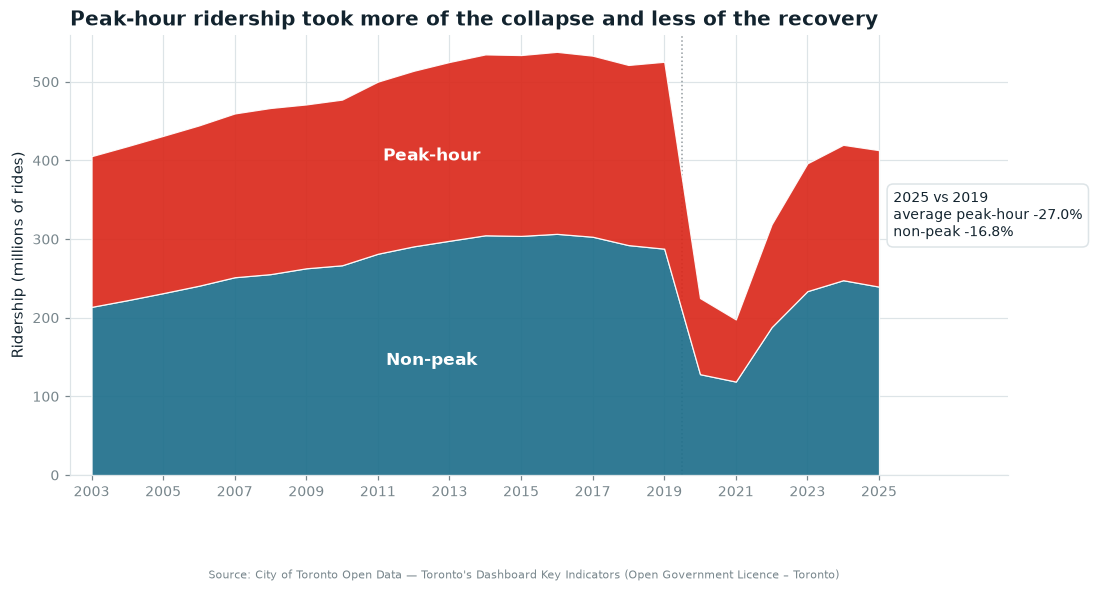

2025 vs 2019: peak-hour -26.99% | non-peak -16.77% | gap 10.2 pts


In [9]:
# --- Section 2.3 - peak vs non-peak composition ---
fig, ax = plt.subplots(figsize=(11, 5.2))

non_m = (annual["non_peak"] / 1e6).to_numpy()
peak_m = (annual["peak"] / 1e6).to_numpy()

ax.stackplot(years, non_m, peak_m, labels=["Non-peak", "Peak-hour"],
             colors=[BLUE, RED], alpha=0.92, edgecolor="white", linewidth=0.8, zorder=2)
ax.axvline(2019.5, color=INK, lw=1, ls=":", alpha=0.45, zorder=1)

# direct labels beat a legend for two stacked bands
ax.text(2012.5, 140, "Non-peak", color="white", fontsize=11, weight="bold",
        ha="center", zorder=3)
ax.text(2012.5, 400, "Peak-hour", color="white", fontsize=11, weight="bold",
        ha="center", zorder=3)

peak_rec = (annual.loc[2025, "peak"] / annual.loc[2019, "peak"] - 1) * 100
non_rec = (annual.loc[2025, "non_peak"] / annual.loc[2019, "non_peak"] - 1) * 100

ax.annotate(f"2025 vs 2019\naverage peak-hour {peak_rec:+.1f}%\nnon-peak {non_rec:+.1f}%",
            xy=(2025.4, 330), fontsize=9, color=INK, ha="left", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.45", fc="white", ec=LIGHT, lw=1))

ax.set_xlim(2002.4, 2028.6)
ax.set_ylim(0, 560)
ax.set_xticks(range(2003, 2026, 2))
ax.set_yticks(range(0, 551, 100))
ax.set_ylabel("Ridership (millions of rides)")
ax.set_title("Peak-hour ridership took more of the collapse and less of the recovery")

png = save_fig(fig, "02_peak_vs_nonpeak")
plt.show()

# --- checks ---
assert (annual["non_peak"] > annual["peak"]).all()
assert np.allclose(annual["peak"] + annual["non_peak"], annual["total"])
assert peak_rec < non_rec, (peak_rec, non_rec)
assert abs(peak_rec + 27.0) < 0.2 and abs(non_rec + 16.7) < 0.2, (peak_rec, non_rec)
assert png.exists() and png.stat().st_size > 30_000, png
print(f"2025 vs 2019: peak-hour {peak_rec:+.2f}% | non-peak {non_rec:+.2f}% "
      f"| gap {non_rec - peak_rec:.1f} pts")

### 2.4 Year-over-year change

Rates, not levels, so the growth era, the plateau and the shock sit on one scale. Splitting
the bars into four eras makes the corrected story legible: eleven years of uninterrupted
growth to 2014, a **four-year plateau** in which ridership fell three times and ended 2.3%
below the 2016 peak, then the 57% collapse of 2020, then a recovery that has already stalled
again in 2025.


saved visualizations/02_yoy_growth.png  (79 KB)


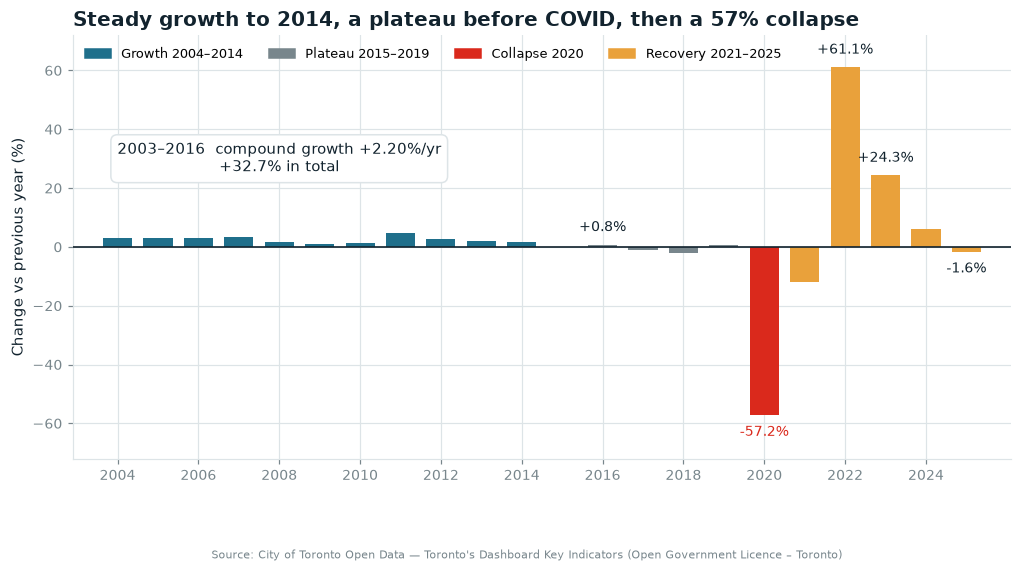

growth 2004-2014: all 11 years up | plateau 2015-2019: 3 down, -2.3% vs 2016 | 2003-2016 CAGR +2.20%/yr | 2025 -1.62%


In [10]:
# --- Section 2.4 - year-over-year change, split by era ---
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(11, 5.0))

yoy = annual["total"].pct_change().mul(100).dropna()
peak_year = int(annual["total"].idxmax())

ERAS = {"growth": (2004, 2014, BLUE),
        "plateau": (2015, 2019, GREY),
        "collapse": (2020, 2020, RED),
        "recovery": (2021, 2025, AMBER)}
colors = [next(c for lo, hi, c in ERAS.values() if lo <= y <= hi) for y in yoy.index]

ax.bar(yoy.index, yoy.to_numpy(), color=colors, width=0.72, zorder=3)
ax.axhline(0, color=INK, lw=1.1, zorder=4)

for year, value in yoy.items():
    if abs(value) >= 20 or year in (peak_year, 2025):
        ax.text(year, value + (3.5 if value > 0 else -3.5), f"{value:+.1f}%",
                ha="center", va="bottom" if value > 0 else "top",
                fontsize=9, color=RED if year == 2020 else INK, zorder=5)

cagr = (annual.loc[peak_year, "total"] / annual.loc[2003, "total"]) ** (1 / (peak_year - 2003)) - 1
ax.annotate(f"2003\u2013{peak_year}  compound growth {cagr * 100:+.2f}%/yr\n"
            f"{(annual.loc[peak_year, 'total'] / annual.loc[2003, 'total'] - 1) * 100:+.1f}% in total",
            xy=(2008, 30), fontsize=9.5, color=INK, ha="center", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.45", fc="white", ec=LIGHT, lw=1))

ax.legend(handles=[Patch(color=c, label=(f"{name.capitalize()} {lo}" if lo == hi
                                          else f"{name.capitalize()} {lo}\u2013{hi}"))
                   for name, (lo, hi, c) in ERAS.items()],
          loc="upper left", ncol=4, fontsize=8.5)
ax.set_xlim(2002.9, 2026.1)
ax.set_ylim(-72, 72)
ax.set_xticks(range(2004, 2026, 2))
ax.set_yticks(range(-60, 61, 20))
ax.set_ylabel("Change vs previous year (%)")
ax.set_title("Steady growth to 2014, a plateau before COVID, then a 57% collapse")

png = save_fig(fig, "02_yoy_growth")
plt.show()

# --- checks ---
assert abs(yoy[2020] + 57.18) < 0.02, yoy[2020]
assert abs(yoy[2022] - 61.11) < 0.02, yoy[2022]
assert 0.021 < cagr < 0.023, cagr
assert yoy.loc[2004:2014].gt(0).all(), "growth era should be all-positive"
assert yoy.loc[2015:2019].lt(0).sum() == 3, yoy.loc[2015:2019].to_dict()
assert (annual.loc[2019, "total"] < annual.loc[peak_year, "total"])
assert png.exists() and png.stat().st_size > 25_000, png
print(f"growth 2004-2014: all {len(yoy.loc[2004:2014])} years up | "
      f"plateau 2015-2019: {int(yoy.loc[2015:2019].lt(0).sum())} down, "
      f"{(annual.loc[2019, 'total'] / annual.loc[peak_year, 'total'] - 1) * 100:+.1f}% vs {peak_year} | "
      f"2003-{peak_year} CAGR {cagr * 100:+.2f}%/yr | 2025 {yoy[2025]:+.2f}%")

## 🗓️ Section 3 — Seasonality

Transit demand is one of the most seasonal things a city does: September and November carry
the year, August and January drag it. This section measures that shape on a **per-day** basis,
which requires the 4-4-5 correction from §1.3 — using raw monthly totals instead inflates the
seasonal swing by roughly 130%, because the 5-week periods land in some months and not others.

The unit throughout is **rides per reporting day**, so a 35-day period and a 28-day period are
directly comparable, and a year is never compared to a partial one.


### 3.1 The seasonal grid, 2008–2026

One row per year, one column per month, colour = average ridership per reporting day.
The horizontal banding is the signal — the same months are strong every year. The pale rows are
2020–2021, when the whole year went dark at once rather than seasonally. 2026 is only observed
through September, so its last three cells are masked rather than filled with an assumption.


saved visualizations/03_seasonality_heatmap.png  (87 KB)


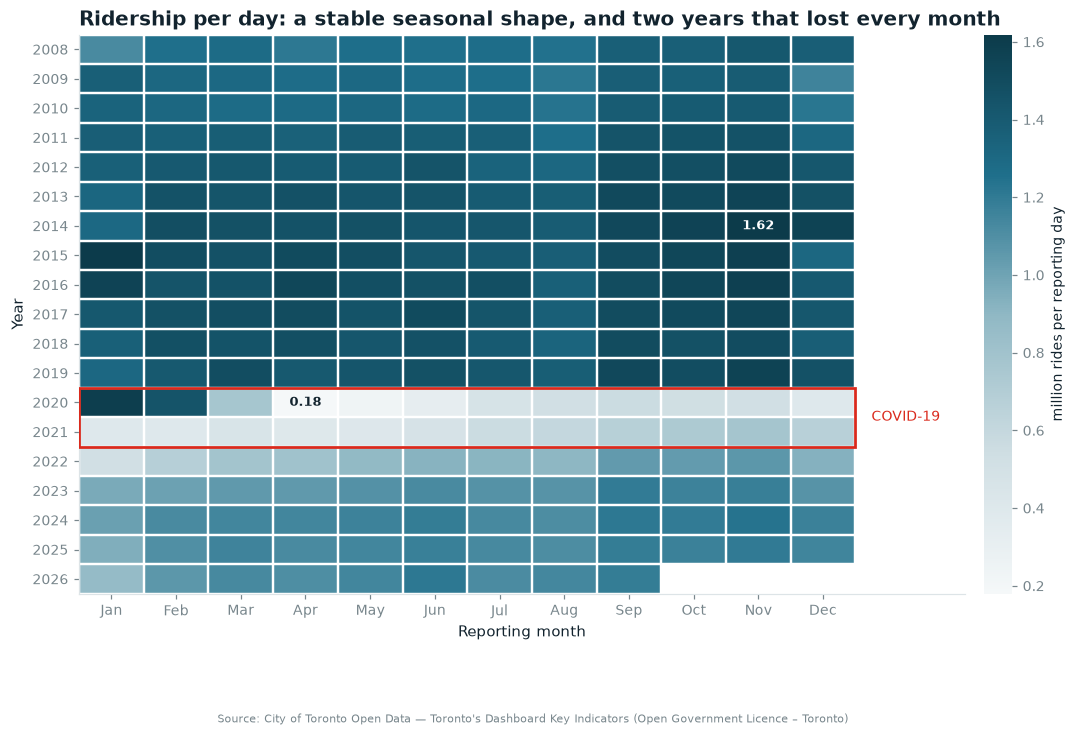

daily grid 19 years x 12 months | high 1.62 M/day (2014 Nov) | low 0.18 M/day (2020 Apr) | 18 complete years


In [11]:
# --- Section 3.1 - average ridership per reporting day, year x month ---
from matplotlib.colors import LinearSegmentedColormap

daily = (monthly.assign(year=monthly.index.year, month=monthly.index.month)
                .pivot(index="year", columns="month", values="rides_per_day")
                .reindex(columns=range(1, 13))
                .div(1e6))                      # millions of rides per day
daily.columns = MONTH_ORDER

# index = month / that year's own average, so the shape is comparable across the collapse
seasonal = daily.div(daily.mean(axis=1), axis=0)
COMPLETE_YEARS = [int(y) for y in daily.index if y != PARTIAL_YEAR]

fig, ax = plt.subplots(figsize=(11, 6.6))
cmap = LinearSegmentedColormap.from_list(
    "ttc", ["#F5F8F9", "#CFDEE3", "#8FB8C4", BLUE, "#0C3B4A"])
cmap.set_bad("white")

data = daily.to_numpy(dtype=float)
im = ax.imshow(data, aspect="auto", cmap=cmap,
               vmin=np.nanmin(data), vmax=np.nanmax(data))

ax.set_xticks(range(12), MONTH_ORDER)
ax.set_yticks(range(len(daily)), [str(y) for y in daily.index])
ax.set_xticks(np.arange(-0.5, 12, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(daily), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.6)
ax.tick_params(which="minor", length=0)
ax.grid(which="major", visible=False)

# the two lost years are the only rows that read as a block rather than a season
band = [i for i, y in enumerate(daily.index) if 2020 <= y <= 2021]
ax.add_patch(plt.Rectangle((-0.5, band[0] - 0.5), 12, len(band),
                           fill=False, ec=RED, lw=1.8, zorder=4))
ax.set_xlim(-0.5, 13.2)          # blank gutter so the band label clears the colorbar
ax.annotate("COVID-19", xy=(11.75, (band[0] + band[-1]) / 2), color=RED, fontsize=9,
            va="center", ha="left", annotation_clip=False)

# mark the strongest and weakest cells on record
hi = np.unravel_index(np.nanargmax(data), data.shape)
lo = np.unravel_index(np.nanargmin(data), data.shape)
ax.text(hi[1], hi[0], f"{data[hi]:.2f}", ha="center", va="center",
        color="white", fontsize=8.5, weight="bold")
ax.text(lo[1], lo[0], f"{data[lo]:.2f}", ha="center", va="center",
        color=INK, fontsize=8.5, weight="bold")

ax.set_xlabel("Reporting month")
ax.set_ylabel("Year")
ax.set_title("Ridership per day: a stable seasonal shape, and two years that lost every month")
cb = fig.colorbar(im, ax=ax, pad=0.02, fraction=0.035)
cb.set_label("million rides per reporting day", fontsize=9)
cb.outline.set_visible(False)

png = save_fig(fig, "03_seasonality_heatmap")
plt.show()

# --- checks ---
assert daily.shape == (19, 12), daily.shape
assert daily.loc[PARTIAL_YEAR].notna().sum() == 9 and daily.loc[PARTIAL_YEAR].isna().sum() == 3
assert daily.loc[2025].notna().all()
assert abs(np.nanmax(data) - 1.62) < 0.01, np.nanmax(data)     # 2014 Nov
assert abs(np.nanmin(data) - 0.18) < 0.01, np.nanmin(data)     # 2020 Apr, the lockdown
assert len(COMPLETE_YEARS) == 18
assert png.exists() and png.stat().st_size > 40_000, png
print(f"daily grid {daily.shape[0]} years x {daily.shape[1]} months | "
      f"high {data[hi]:.2f} M/day ({daily.index[hi[0]]} {MONTH_ORDER[hi[1]]}) | "
      f"low {data[lo]:.2f} M/day ({daily.index[lo[0]]} {MONTH_ORDER[lo[1]]}) | "
      f"{len(COMPLETE_YEARS)} complete years")

### 3.2 The shape has deepened, not flattened

Indexing each month against its own year's average removes the collapse and leaves only the
seasonal shape, so eras can be compared directly. The result is the opposite of what the
"commuting never came back" story would predict: seasonality has **not** flattened. It has
become **more** pronounced, because the weakest months got weaker.

- **November is the strongest month** in every pre-pandemic era — not September, which is
  strong but second.
- The trough moved: **August** before 2020, **January** after, at an index of 0.87 — the
  weakest month in the whole record.
- Spread between best and worst month: 14% (2008–14) → 13% (2015–19) → **20% (2023–25)**.

The grey 2020–22 line is plotted for completeness but should not be read as seasonality: that
era collapsed *within* each year, so its January index of 1.29 is an artifact of measuring two
pre-lockdown months against a depressed annual average, not evidence of a strong January.


saved visualizations/03_seasonality_era.png  (139 KB)


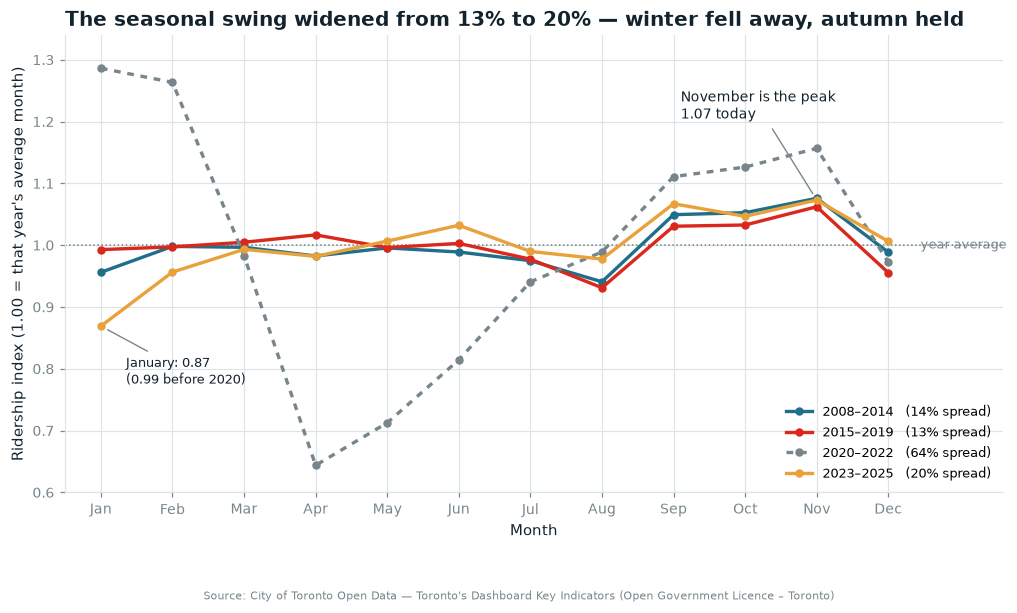

spread by era: 2008–2014 14% | 2015–2019 13% | 2020–2022 64% | 2023–2025 20%
2023-25: Nov 1.073 (peak) | Jan 0.869 (trough) | Sep/Aug 1.092
2015-19: Nov 1.062 (peak) | Aug 0.931 (trough) | Sep/Aug 1.107


In [12]:
# --- Section 3.2 - seasonality index by era ---
ERAS = {
    "2008\u20132014": (2008, 2014, BLUE, "-"),
    "2015\u20132019": (2015, 2019, RED, "-"),
    "2020\u20132022": (2020, 2022, GREY, (0, (2, 2))),   # pandemic: shape destroyed, not seasonal
    "2023\u20132025": (2023, 2025, AMBER, "-"),
}
era_index = pd.DataFrame({label: seasonal.loc[lo:hi].mean()
                          for label, (lo, hi, _, _) in ERAS.items()})

fig, ax = plt.subplots(figsize=(11, 5.4))
x = np.arange(len(MONTH_ORDER))

for label, (lo, hi, color, style) in ERAS.items():
    series = era_index[label]
    spread = (series.max() - series.min()) * 100
    ax.plot(x, series.to_numpy(), color=color, lw=2.2, ls=style, marker="o", ms=4.5,
            label=f"{label}   ({spread:.0f}% spread)", zorder=3)

ax.axhline(1.0, color=INK, lw=1, ls=":", alpha=0.55, zorder=2)
ax.text(11.45, 1.0, "year average", fontsize=8.5, color=GREY, va="center", ha="left")

modern = era_index["2023\u20132025"]
pre = era_index["2015\u20132019"]
ax.annotate(f"November is the peak\n{modern['Nov']:.2f} today",
            xy=(x[10], modern["Nov"]), xytext=(8.1, 1.225), fontsize=9, color=INK,
            ha="left", va="center", zorder=5,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9, shrinkA=2, shrinkB=5))
ax.annotate(f"January: {modern['Jan']:.2f}\n({pre['Jan']:.2f} before 2020)",
            xy=(x[0], modern["Jan"]), xytext=(0.35, 0.795), fontsize=8.5, color=INK,
            ha="left", va="center", zorder=5,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9, shrinkA=2, shrinkB=5))

ax.set_xticks(x, MONTH_ORDER)
ax.set_xlim(-0.5, 12.6)
ax.set_ylim(0.60, 1.34)
ax.set_ylabel("Ridership index (1.00 = that year's average month)")
ax.set_xlabel("Month")
ax.set_title("The seasonal swing widened from 13% to 20% — winter fell away, autumn held")
ax.legend(loc="lower right", fontsize=8.5, ncol=1)

png = save_fig(fig, "03_seasonality_era")
plt.show()

# --- checks ---
spread = {k: float((v.max() - v.min()) * 100) for k, v in era_index.items()}
assert era_index["2023\u20132025"].idxmax() == "Nov", era_index["2023\u20132025"].idxmax()
assert era_index["2008\u20132014"].idxmax() == "Nov"
assert era_index["2008\u20132014"].idxmin() == "Aug"
assert era_index["2015\u20132019"].idxmin() == "Aug"
assert era_index["2023\u20132025"].idxmin() == "Jan"
assert spread["2023\u20132025"] > spread["2015\u20132019"], spread
assert abs(spread["2023\u20132025"] - 20) < 1.5 and abs(spread["2015\u20132019"] - 13) < 1.5, spread
assert modern["Jan"] < pre["Jan"] - 0.10
print("spread by era: " + " | ".join(f"{k} {v:.0f}%" for k, v in spread.items()))
print(f"2023-25: Nov {modern['Nov']:.3f} (peak) | Jan {modern['Jan']:.3f} (trough) "
      f"| Sep/Aug {modern['Sep'] / modern['Aug']:.3f}")
print(f"2015-19: Nov {pre['Nov']:.3f} (peak) | Aug {pre['Aug']:.3f} (trough) "
      f"| Sep/Aug {pre['Sep'] / pre['Aug']:.3f}")

### 3.3 Why the raw series lies about seasonality

Same year, same months, two ways of measuring. The bars index the **published monthly totals**
against their own annual average; the line indexes **ridership per reporting day**. They should
agree — they are the same ridership — and they disagree by up to 15 percentage points.

The reason is the 4-4-5 calendar from §1.3: March and June are always 5-week periods, so their
totals contain ~25% more days than April or May and read as a demand spike. Dividing by reporting
days removes it. Across the twelve months, the raw index varies **2.3× more** than the true
seasonal shape.


saved visualizations/03_445_artifact.png  (123 KB)


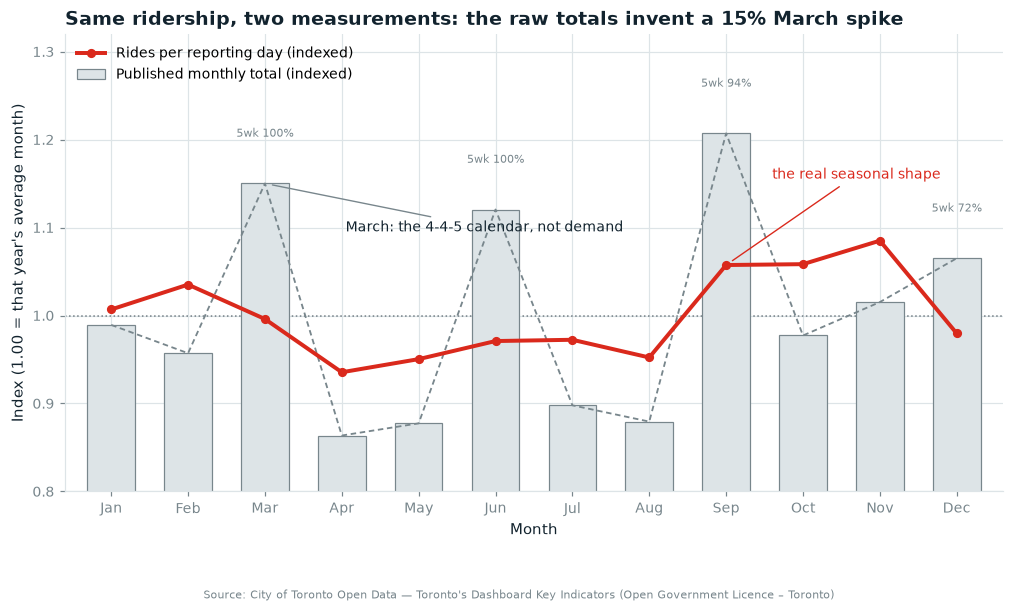

index spread across months: raw 0.115 vs per-day 0.049  (2.36x)
March overstated by +15.5% | May understated by -7.7% | 5-week in >90% of years: ['Mar', 'Jun', 'Sep']


In [13]:
# --- Section 3.3 - raw monthly totals vs rides per reporting day ---
raw = (monthly.assign(year=monthly.index.year, month=monthly.index.month)
              .pivot(index="year", columns="month", values="ridership")
              .reindex(columns=range(1, 13)))
raw.columns = MONTH_ORDER

raw_index = raw.div(raw.mean(axis=1), axis=0).loc[COMPLETE_YEARS]
mean_raw = raw_index.mean()
mean_per_day = seasonal.loc[COMPLETE_YEARS].mean()

# months that were 5-week periods in the years being averaged (period table from 1.3)
five_share = (periods.query("period_weeks == 5 and year in @COMPLETE_YEARS")
                     .groupby("period", observed=True).size()
                     .reindex(MONTH_ORDER).fillna(0) / len(COMPLETE_YEARS))

fig, ax = plt.subplots(figsize=(11, 5.4))
x = np.arange(len(MONTH_ORDER))

ax.bar(x, mean_raw.to_numpy(), width=0.62, color=LIGHT, edgecolor=GREY, linewidth=0.8,
       zorder=2, label="Published monthly total (indexed)")
ax.plot(x, mean_raw.to_numpy(), color=GREY, lw=1.2, ls=(0, (3, 2)), zorder=3)
ax.plot(x, mean_per_day.to_numpy(), color=RED, lw=2.6, marker="o", ms=5, zorder=4,
        label="Rides per reporting day (indexed)")

ax.axhline(1.0, color=INK, lw=1, ls=":", alpha=0.55, zorder=1)

for i, month in enumerate(MONTH_ORDER):
    if five_share[month] > 0.5:
        ax.annotate(f"5wk {five_share[month]:.0%}", xy=(i, mean_raw[month]),
                    xytext=(i, mean_raw[month] + 0.05), fontsize=7.5, color=GREY,
                    ha="center", va="bottom", zorder=5)

ax.annotate("March: the 4-4-5 calendar, not demand",
            xy=(x[2], mean_raw["Mar"]), xytext=(3.05, 1.10), fontsize=9, color=INK,
            ha="left", va="center", zorder=6,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9, shrinkA=2, shrinkB=5))
ax.annotate("the real seasonal shape",
            xy=(x[8], mean_per_day["Sep"]), xytext=(8.6, 1.16), fontsize=9, color=RED,
            ha="left", va="center", zorder=6,
            arrowprops=dict(arrowstyle="-", color=RED, lw=0.9, shrinkA=2, shrinkB=5))

ax.set_xticks(x, MONTH_ORDER)
ax.set_xlim(-0.6, 11.6)
ax.set_ylim(0.80, 1.32)
ax.set_ylabel("Index (1.00 = that year's average month)")
ax.set_xlabel("Month")
ax.set_title("Same ridership, two measurements: the raw totals invent a 15% March spike", fontsize=12.5)
ax.legend(loc="upper left", fontsize=9)

png = save_fig(fig, "03_445_artifact")
plt.show()

# --- checks ---
assert abs(mean_raw["Mar"] - 1.15) < 0.01, mean_raw["Mar"]
assert abs(mean_per_day["Mar"] - 1.00) < 0.02, mean_per_day["Mar"]
assert mean_raw["Sep"] > 1.19 and mean_per_day["Sep"] < 1.08
assert mean_raw.std() > 2 * mean_per_day.std(), (mean_raw.std(), mean_per_day.std())
for month in ("Mar", "Jun"):
    assert five_share[month] == 1.0, (month, five_share[month])
assert five_share["Sep"] > 0.9, five_share["Sep"]   # every year but 2018
assert png.exists() and png.stat().st_size > 35_000, png
print(f"index spread across months: raw {mean_raw.std():.3f} vs per-day "
      f"{mean_per_day.std():.3f}  ({mean_raw.std() / mean_per_day.std():.2f}x)")
print(f"March overstated by {(mean_raw['Mar'] / mean_per_day['Mar'] - 1) * 100:+.1f}% | "
      f"May understated by {(mean_raw['May'] / mean_per_day['May'] - 1) * 100:+.1f}% | "
      f"5-week in >90% of years: {[m for m in MONTH_ORDER if five_share[m] > 0.9]}")

## 📉 Section 4 — The shock, and how far the recovery got

Section 2 measured the collapse annually. This section measures it monthly, against a
**2019 baseline**, which is the only way to see how fast it happened and how unevenly it came back.

Every comparison here is made on a **per-reporting-day** basis, and that matters more than it
sounds. Indexing raw monthly totals against the same month of 2019 produces a December 2025
figure of 98.5% — apparently a full recovery — because December 2019 was a **4-week** period and
December 2025 was a **5-week** one (under the calendar inferred in §1.3). Dividing by reporting days first puts December 2025 at
78.8%, in line with every other month. The 4-4-5 calendar makes the naive index wrong by up to
25 percentage points in the recovery's favour.


### 4.1 Depth and speed of the shock

Each point is a reporting month's ridership per day as a percentage of the same calendar month in
2019. Indexing month-for-month cancels seasonality, so the line shows only the shock and the
climb — 2019 itself sits flat on the 100 line by construction.

The drop is abrupt: January 2020 was still **122%** of January 2019, March was 52%, and April
was **12.8%**. The climb back takes five years and then stops short of 80%.


saved visualizations/04_recovery_index.png  (109 KB)


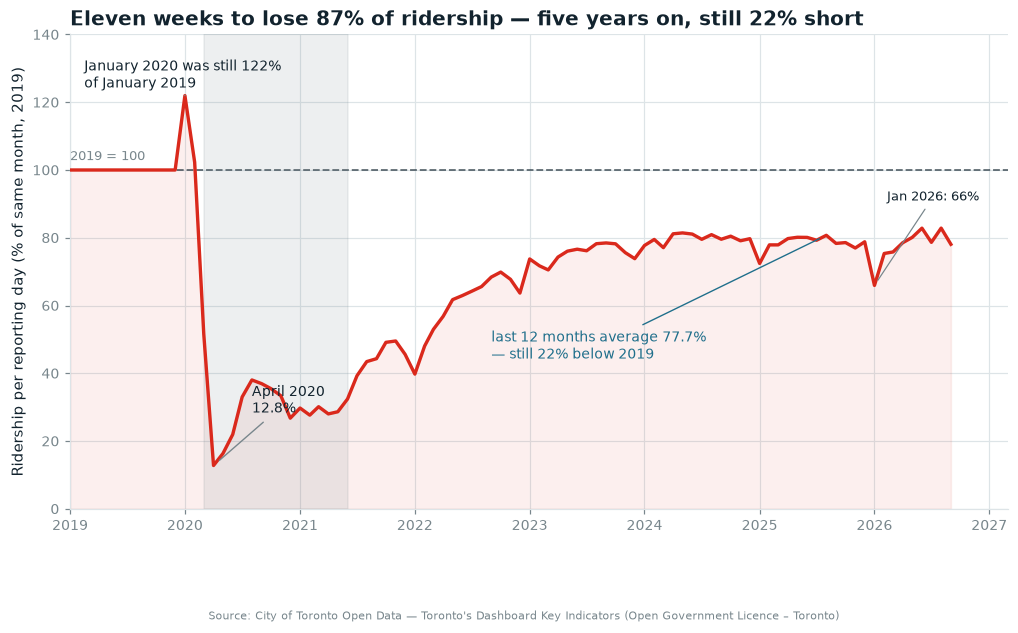

Apr 2020 12.8% | recovery holds 65.9-82.8% over the last 12 months | Dec 2025 raw-total index 98.5% vs per-day 78.8%


In [14]:
# --- Section 4.1 - ridership per reporting day, indexed to the same month of 2019 ---
per_day = monthly["rides_per_day"].astype(float)

base_2019 = per_day.loc["2019"].groupby(per_day.loc["2019"].index.month).first()
vs2019 = per_day.div(per_day.index.month.map(base_2019)).mul(100)

plot_from = "2019-01-01"
recent = vs2019.loc[plot_from:]

fig, ax = plt.subplots(figsize=(11, 5.6))
ax.fill_between(recent.index, 0, recent.to_numpy(), color=RED, alpha=0.07, zorder=1)
ax.plot(recent.index, recent.to_numpy(), color=RED, lw=2.2, zorder=3)
ax.axhline(100, color=INK, lw=1.2, ls="--", alpha=0.65, zorder=2)
ax.text(recent.index[0], 102, "2019 = 100", fontsize=8.5, color=GREY, va="bottom")

ax.annotate(f"April 2020\n{vs2019.loc['2020-04-01']:.1f}%",
            xy=(pd.Timestamp("2020-04-01"), vs2019.loc["2020-04-01"]),
            xytext=(pd.Timestamp("2020-08-01"), 32), fontsize=9, color=INK, ha="left",
            va="center", zorder=5,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9, shrinkA=2, shrinkB=5))
ax.annotate("January 2020 was still 122%\nof January 2019",
            xy=(pd.Timestamp("2020-01-01"), vs2019.loc["2020-01-01"]),
            xytext=(pd.Timestamp("2019-02-15"), 128), fontsize=9, color=INK, ha="left",
            va="center", zorder=5,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9, shrinkA=2, shrinkB=5))
last12 = vs2019.iloc[-12:]
ax.annotate(f"last 12 months average {last12.mean():.1f}%\n"
            f"\u2014 still {100 - last12.mean():.0f}% below 2019",
            xy=(pd.Timestamp("2025-08-01"), vs2019.loc["2025-08-01"]),
            xytext=(pd.Timestamp("2022-09-01"), 48), fontsize=9, color=BLUE, ha="left",
            va="center", zorder=5,
            arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.9, shrinkA=2, shrinkB=5))
ax.annotate(f"Jan 2026: {vs2019.loc['2026-01-01']:.0f}%",
            xy=(pd.Timestamp("2026-01-01"), vs2019.loc["2026-01-01"]),
            xytext=(pd.Timestamp("2026-02-10"), 92), fontsize=8.5, color=INK, ha="left",
            va="center", zorder=5,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8, shrinkA=2, shrinkB=4))

ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color=GREY,
           alpha=0.13, zorder=2)
ax.set_ylim(0, 140)
ax.set_xlim(pd.Timestamp("2019-01-01"), pd.Timestamp("2027-03-01"))
ax.set_ylabel("Ridership per reporting day (% of same month, 2019)")
ax.set_title("Eleven weeks to lose 87% of ridership \u2014 five years on, still 22% short")

png = save_fig(fig, "04_recovery_index")
plt.show()

# --- checks ---
assert np.isclose(vs2019.loc["2019"].round(6), 100).all(), vs2019.loc["2019"]
assert vs2019.loc["2020":].idxmin() == pd.Timestamp("2020-04-01"), vs2019.loc["2020":].idxmin()
assert abs(vs2019.loc["2020-04-01"] - 12.8) < 0.1, vs2019.loc["2020-04-01"]
assert abs(vs2019.loc["2020-03-01"] - 51.5) < 0.1 and abs(vs2019.loc["2020-05-01"] - 16.3) < 0.1
assert vs2019.loc["2020-01-01"] > 120
# the 4-4-5 trap: on raw totals December 2025 would read 98.5%, on a per-day basis it must not
raw_dec = monthly.loc["2025-12-01", "ridership"] / monthly.loc["2019-12-01", "ridership"] * 100
assert raw_dec > 96, raw_dec
assert vs2019.loc["2025-12-01"] < 82, vs2019.loc["2025-12-01"]
assert 76 < vs2019.iloc[-12:].mean() < 82
assert png.exists() and png.stat().st_size > 40_000, png
print(f"Apr 2020 {vs2019.loc['2020-04-01']:.1f}% | recovery holds "
      f"{vs2019.iloc[-12:].min():.1f}-{vs2019.iloc[-12:].max():.1f}% over the last 12 months | "
      f"Dec 2025 raw-total index {raw_dec:.1f}% vs per-day {vs2019.loc['2025-12-01']:.1f}%")

### 4.2 Which months came back

Same index, read across the calendar instead of through time: every month of 2025 as a share of
the same month in 2019. Ten of twelve months sit in a tight 77–81% band — but **January is at
72%**, and it is getting worse, not better: 77.7% in 2024, 72.4% in 2025, 65.9% in January 2026.

That is the same winter weakness Section 3 found in the seasonal shape, seen from the recovery
side. The months that lost the most are the ones that have come back least.


saved visualizations/04_recovery_by_month.png  (92 KB)


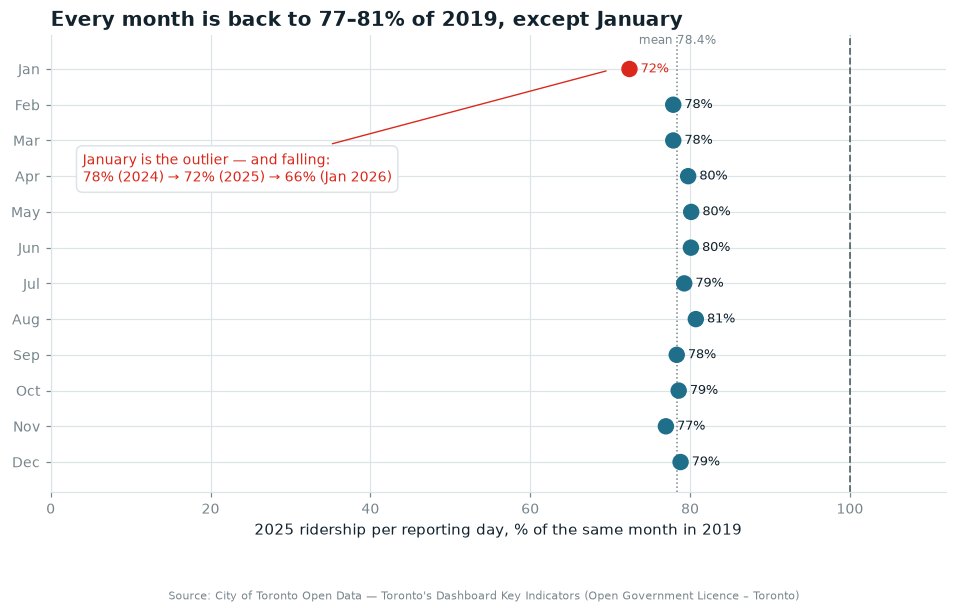

2025 by month: mean 78.4% | best Aug 80.7% | worst Jan 72.4%
eleven non-January months span only 77.0-80.7% - small, and shown at true scale
January path: 2024 77.7% -> 2025 72.4% -> 2026 65.9%


In [15]:
# --- Section 4.2 - recovery completeness by calendar month (2025 vs 2019) ---
recovery_2025 = vs2019.loc["2025"].groupby(vs2019.loc["2025"].index.month).first()
january_path = [vs2019.loc[f"{y}-01-01"] for y in (2024, 2025, 2026)]

fig, ax = plt.subplots(figsize=(10.5, 5.4))
ypos = np.arange(12)[::-1]                      # January at the top
colors = [RED if m == 1 else BLUE for m in range(1, 13)]

# Dots, not bars. A bar encodes length, so a bar chart starting at 60% would exaggerate
# these differences; a dot encodes position, and this axis starts at zero anyway.
ax.scatter(recovery_2025.to_numpy(), ypos, s=95, color=colors, zorder=4)
ax.axvline(100, color=INK, lw=1.2, ls="--", alpha=0.65, zorder=2)
ax.axvline(recovery_2025.mean(), color=GREY, lw=1, ls=":", zorder=2)

for y, month, value in zip(ypos, range(1, 13), recovery_2025.to_numpy()):
    ax.text(value + 1.4, y, f"{value:.0f}%", va="center", ha="left",
            fontsize=8.5, color=RED if month == 1 else INK, zorder=4)

ax.annotate("January is the outlier \u2014 and falling:\n"
            f"{january_path[0]:.0f}% (2024) \u2192 {january_path[1]:.0f}% (2025) "
            f"\u2192 {january_path[2]:.0f}% (Jan 2026)",
            xy=(recovery_2025.loc[1] - 2.0, ypos[0]), xytext=(4, 8.2),
            fontsize=9, color=RED, ha="left", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.45", fc="white", ec=LIGHT, lw=1),
            arrowprops=dict(arrowstyle="-", color=RED, lw=0.9, shrinkA=4, shrinkB=5))

ax.text(recovery_2025.mean(), ypos[0] + 0.62, f"mean {recovery_2025.mean():.1f}%",
        fontsize=8, color=GREY, ha="center", va="bottom")
ax.set_yticks(ypos, MONTH_ORDER)
ax.set_xlim(0, 112)
ax.set_ylim(-0.85, 11.95)
ax.set_xlabel("2025 ridership per reporting day, % of the same month in 2019")
ax.set_title("Every month is back to 77\u201381% of 2019, except January")

png = save_fig(fig, "04_recovery_by_month")
plt.show()

# --- checks ---
assert len(recovery_2025) == 12 and recovery_2025.notna().all()
assert recovery_2025.idxmin() == 1, recovery_2025.idxmin()
assert abs(recovery_2025.loc[1] - 72.4) < 0.2, recovery_2025.loc[1]
assert recovery_2025.drop(1).between(76, 82).all(), recovery_2025.drop(1)
assert january_path[0] > january_path[1] > january_path[2], january_path
assert abs(january_path[2] - 65.9) < 0.2, january_path[2]
assert png.exists() and png.stat().st_size > 35_000, png
print(f"2025 by month: mean {recovery_2025.mean():.1f}% | best "
      f"{MONTH_ORDER[recovery_2025.idxmax() - 1]} {recovery_2025.max():.1f}% | worst "
      f"{MONTH_ORDER[recovery_2025.idxmin() - 1]} {recovery_2025.min():.1f}%")
print(f"eleven non-January months span only "
      f"{recovery_2025.drop(1).min():.1f}-{recovery_2025.drop(1).max():.1f}% - small, and shown at true scale")
print("January path: " + " -> ".join(f"{y} {v:.1f}%" for y, v in
                                     zip((2024, 2025, 2026), january_path)))

### 4.3 The recovery plateaued in 2024

Comparing whole years is impossible here — 2026 has no autumn — so this chart compares
**January-to-September in every year**, converted to a rides-per-reporting-day rate before
indexing to 2019. That makes all eight years strictly comparable, including the partial one.

The recovery climbed for three years, peaked at **79.9% in 2024**, and has slipped for two
consecutive years: 78.7% in 2025, 77.9% in 2026. Ridership is not recovering any more; it is
drifting down a point or so a year.


saved visualizations/04_recovery_ladder.png  (72 KB)


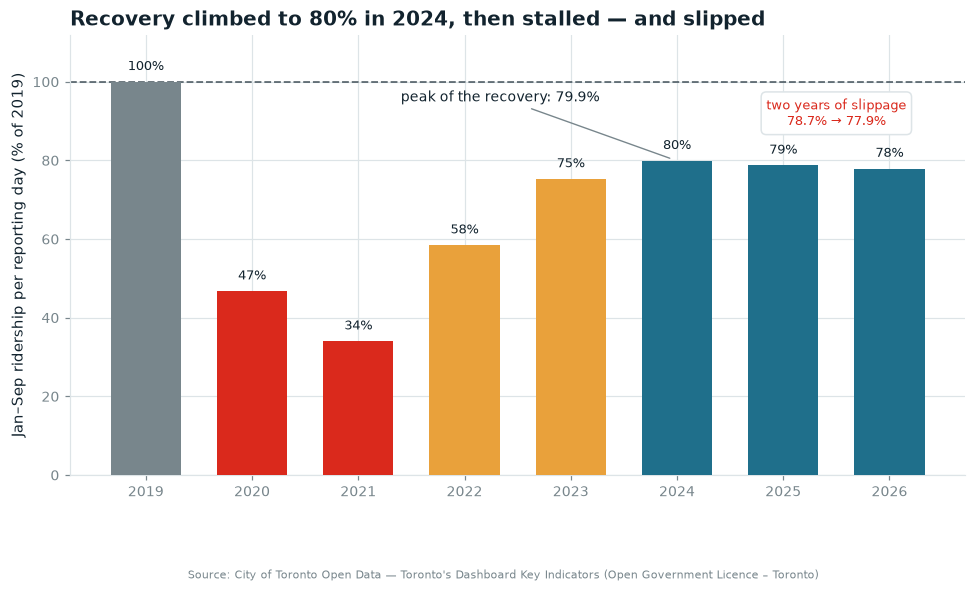

YTD Jan-Sep per-day index: 2019 100.0% | 2020 46.8% | 2021 34.0% | 2022 58.4% | 2023 75.3% | 2024 79.9% | 2025 78.7% | 2026 77.9%
reporting days in Jan-Sep: 2019 280, 2026 273 (the reason raw totals would understate the rate)


In [16]:
# --- Section 4.3 - year-to-date recovery ladder, per reporting day ---
ytd_part = monthly[monthly.index.month <= 9]        # Jan-Sep exists in every year, including 2026
ytd_rides = ytd_part["ridership"].groupby(ytd_part.index.year).sum()
ytd_days = ytd_part["period_days"].groupby(ytd_part.index.year).sum()
ytd_rate = ytd_rides / ytd_days
ytd_index = ytd_rate.div(ytd_rate.loc[2019]).mul(100).loc[2019:]

fig, ax = plt.subplots(figsize=(10.5, 5.2))
years_x = ytd_index.index.to_numpy()
colors = [GREY if y == 2019 else RED if y <= 2021 else AMBER if y <= 2023 else BLUE
          for y in years_x]

ax.bar(years_x, ytd_index.to_numpy(), color=colors, width=0.66, zorder=3)
ax.axhline(100, color=INK, lw=1.2, ls="--", alpha=0.65, zorder=2)

for year, value in ytd_index.items():
    ax.text(year, value + 2.2, f"{value:.0f}%", ha="center", va="bottom",
            fontsize=8.5, color=INK, zorder=4)

since_covid = ytd_index.loc[2020:]              # the recovery peak, not the 2019 baseline
peak_year, peak_value = int(since_covid.idxmax()), float(since_covid.max())

ax.annotate(f"peak of the recovery: {peak_value:.1f}%",
            xy=(peak_year, peak_value), xytext=(2021.4, 96), fontsize=9, color=INK,
            ha="left", va="center", zorder=5,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9, shrinkA=2, shrinkB=5))
ax.text(2025.5, 92, f"two years of slippage\n{ytd_index.loc[2025]:.1f}% \u2192 {ytd_index.loc[2026]:.1f}%",
        fontsize=8.5, color=RED, ha="center", va="center", zorder=6,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=LIGHT, lw=1))

ax.set_xticks(years_x)
ax.set_ylim(0, 112)
ax.set_ylabel("Jan\u2013Sep ridership per reporting day (% of 2019)")
ax.set_title(f"Recovery climbed to {peak_value:.0f}% in {peak_year}, then stalled \u2014 and slipped")
png = save_fig(fig, "04_recovery_ladder")
plt.show()

# --- checks ---
assert list(ytd_index.index) == [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
assert np.isclose(ytd_index.loc[2019], 100.0)
assert int(ytd_index.idxmin()) == 2021, ytd_index.idxmin()   # trough of the ladder
assert peak_year == 2024 and abs(peak_value - 79.9) < 0.2, (peak_year, peak_value)
assert ytd_index.loc[2024] > ytd_index.loc[2025] > ytd_index.loc[2026], ytd_index.tail(3).to_dict()
# the ladder must agree with the raw YTD comparison for the honest 2026 statement
assert abs(ytd_rides[2026] / ytd_rides[2025] - 1 + 0.0102) < 5e-4
assert abs(ytd_days.loc[2019] - 280) < 1 and abs(ytd_days.loc[2026] - 273) < 1
assert png.exists() and png.stat().st_size > 35_000, png
print("YTD Jan-Sep per-day index: " +
      " | ".join(f"{y} {v:.1f}%" for y, v in ytd_index.items()))
print(f"reporting days in Jan-Sep: 2019 {int(ytd_days.loc[2019])}, 2026 {int(ytd_days.loc[2026])} "
      f"(the reason raw totals would understate the rate)")

## 🕔 Section 5 — Peak vs non-peak: a pre-pandemic story

Peak-hour and non-peak ridership are published as separate annual measures, which makes the
peak-hour travel visible on its own. Two things come out of this section: a real, measured shift in
the peak-hour share between 2003 and 2019, and a **round-number pattern** that stops the series
being usable as evidence after 2021.

The pattern is worth the space. From 2022 the published peak-halves are *exactly* a round
percentage of the total — 41.0001%, 41.0001%, 41.0000%, 42.0000%. Independent measurement would
not land on four whole percentages in a row, so the split in those years looks rounded or
estimated rather than observed, and the recent "recovery" of the peak-hour share from 39.9% to
42% is not usable as evidence. Confirming it would need TTC's methodology notes, which are not
published.


### 5.1 Peak-hour share, and a round-number pattern

Share of all rides taken in the peak hours, in three phases: **47.3% in 2003 falling to 43.0% by
2014**, a **rebound to 45.2% by 2019**, then a collapse to **39.9% in 2021**. The middle phase is
the interesting one — peak-hour share *rose* in 2017–2019 even as total ridership was falling, so
the pre-pandemic slippage was in off-peak travel rather than peak.

The hollow markers are a caution flag, not a finding. In those years the published share lands on
a whole percentage to four decimal places — 2022, 2023 and 2024 are 41.0001%, 41.0001% and
41.0000% of the total, and 2025 is 42.0000%. Rounding or estimation would produce that; an
independently measured split would not. It is **not** proof that the figures were constructed, and
it says nothing about how the other years were produced — only that in those seven years the split
carries no information beyond the annual total, so it should not be used as evidence either way.
Confirming this would need TTC's own methodology notes, which are not published.


saved visualizations/05_peak_share.png  (115 KB)


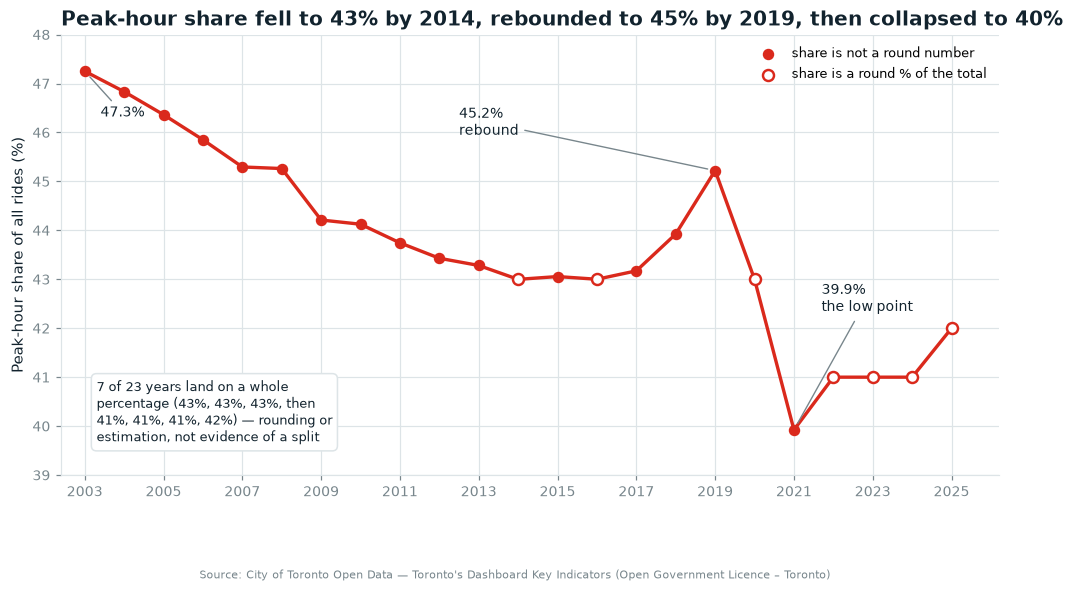

peak-hour share 47.25% (2003) -> 45.22% (2019) -> 39.92% (2021)
years landing on a whole percentage: [2014, 2016, 2020, 2022, 2023, 2024, 2025] (7 of 23) - a caution flag, not proof of construction
closest any other year comes to a round number: 0.056pp


In [17]:
# --- Section 5.1 - peak-hour share, with a round-number check on the published split ---
share = annual["peak_share"].mul(100)
off_round = (share - share.round()).abs()
round_number = off_round < 0.01        # whole percentage to 4dp -> rounding or estimation
other_years = ~round_number

fig, ax = plt.subplots(figsize=(11, 5.2))

ax.plot(share.index, share.to_numpy(), color=RED, lw=2.2, zorder=3)
ax.scatter(share.index[other_years], share[other_years], s=42, color=RED, zorder=4,
           label="share is not a round number")
ax.scatter(share.index[round_number], share[round_number], s=52, facecolor="white",
           edgecolor=RED, linewidth=1.6, zorder=5,
           label="share is a round % of the total")

ax.annotate("7 of 23 years land on a whole\npercentage (43%, 43%, 43%, then\n"
            "41%, 41%, 41%, 42%) \u2014 rounding or\nestimation, not evidence of a split",
            xy=(2003.3, 39.6), fontsize=8.5, color=INK, ha="left", va="bottom", zorder=6,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=LIGHT, lw=1))

ax.annotate(f"{share.loc[2003]:.1f}%", xy=(2003, share.loc[2003]), xytext=(2003.4, 46.4),
            fontsize=9, color=INK, va="center",
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9, shrinkA=2, shrinkB=5))
ax.annotate(f"{share.loc[2019]:.1f}%\nrebound", xy=(2019, share.loc[2019]),
            xytext=(2012.5, 46.2), fontsize=9, color=INK, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9, shrinkA=2, shrinkB=5))
ax.annotate(f"{share.loc[2021]:.1f}%\nthe low point", xy=(2021, share.loc[2021]),
            xytext=(2021.7, 42.6), fontsize=9, color=INK, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9, shrinkA=2, shrinkB=5))

ax.set_xlim(2002.4, 2026.2)
ax.set_ylim(39, 48)
ax.set_xticks(range(2003, 2026, 2))
ax.set_ylabel("Peak-hour share of all rides (%)")
ax.set_title("Peak-hour share fell to 43% by 2014, rebounded to 45% by 2019, then collapsed to 40%")
ax.legend(loc="upper right", fontsize=8.5)

png = save_fig(fig, "05_peak_share")
plt.show()

# --- checks ---
assert len(share) == 23 and share.between(39, 48).all()
assert abs(share.loc[2003] - 47.25) < 0.01 and abs(share.loc[2021] - 39.92) < 0.01
assert abs(share.loc[2019] - 45.22) < 0.01
assert list(share.index[round_number]) == [2014, 2016, 2020, 2022, 2023, 2024, 2025]
for year, pct in ((2022, 41), (2023, 41), (2024, 41), (2025, 42)):
    assert abs(share.loc[year] - pct) < 0.01, (year, share.loc[year])
assert np.allclose(annual["peak"] + annual["non_peak"], annual["total"])
assert png.exists() and png.stat().st_size > 35_000, png
print(f"peak-hour share {share.loc[2003]:.2f}% (2003) -> {share.loc[2019]:.2f}% (2019) "
      f"-> {share.loc[2021]:.2f}% (2021)")
print(f"years landing on a whole percentage: {list(share.index[round_number])} "
      f"({int(round_number.sum())} of 23) - a caution flag, not proof of construction")
print(f"closest any other year comes to a round number: {off_round[other_years].min():.3f}pp")

### 5.2 The two halves diverged

Indexing both measures to 2019 isolates their behaviour: through 2021 the split is not a round
number, and peak-hour ridership falls further and recovers more slowly than non-peak. Peak-hour
sits at **73.0** of 2019 in 2025 against non-peak at **83.2**.

Read that gap with the caveat above. In 2022–2025 the split is arithmetically tied to the annual
total, so the two 2025 figures are not independent measurements — they are the total divided by
41–42%. The *direction* (peak weaker than non-peak) is consistent in every year from 2015 to 2021,
where the split is not a round number, so it is plausibly real; the exact 2025 numbers are not
evidence on their own. Section 6 offers an independent check on the same question using a
different column.


saved visualizations/05_peak_vs_nonpeak_index.png  (93 KB)


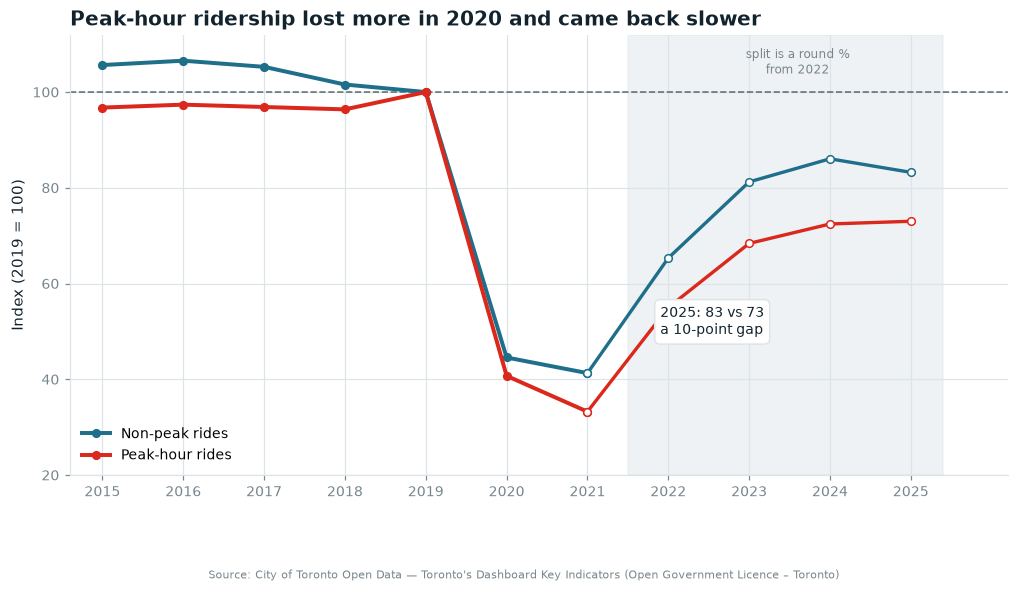

2019 = 100 | 2021 peak 33.2 vs non-peak 41.3 (measured)
             2025 peak 73.0 vs non-peak 83.2 (round-% split)


In [18]:
# --- Section 5.2 - peak vs non-peak, indexed to 2019 ---
indexed = pd.DataFrame({
    "peak": annual["peak"] / annual.loc[2019, "peak"] * 100,
    "non_peak": annual["non_peak"] / annual.loc[2019, "non_peak"] * 100,
}).loc[2015:]

fig, ax = plt.subplots(figsize=(11, 5.2))

for col, color, label in (("non_peak", BLUE, "Non-peak rides"),
                          ("peak", RED, "Peak-hour rides")):
    solid = indexed.loc[:2021, col]
    dashed = indexed.loc[2021:, col]
    ax.plot(solid.index, solid.to_numpy(), color=color, lw=2.6, marker="o", ms=5,
            zorder=4, label=label)
    ax.plot(dashed.index, dashed.to_numpy(), color=color, lw=2.2, marker="o", ms=5,
            mfc="white", zorder=4)

ax.axhline(100, color=INK, lw=1.1, ls="--", alpha=0.6, zorder=2)
ax.axvspan(2021.5, indexed.index.max() + 0.4, color=LIGHT, alpha=0.45, zorder=0)

ax.annotate(f"2025: {indexed.loc[2025, 'non_peak']:.0f} vs "
            f"{indexed.loc[2025, 'peak']:.0f}\n"
            f"a {indexed.loc[2025, 'non_peak'] - indexed.loc[2025, 'peak']:.0f}-point gap",
            xy=(2025, indexed.loc[2025, "peak"] + 3), xytext=(2021.9, 52), fontsize=9,
            color=INK, ha="left", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=LIGHT, lw=1))
ax.text(2023.6, 103, "split is a round %\nfrom 2022", fontsize=8, color=GREY,
        ha="center", va="bottom")

ax.set_xlim(2014.6, 2026.2)
ax.set_ylim(20, 112)
ax.set_xticks(range(2015, 2026, 1))
ax.set_ylabel("Index (2019 = 100)")
ax.set_title("Peak-hour ridership lost more in 2020 and came back slower")
ax.legend(loc="lower left", fontsize=9)

png = save_fig(fig, "05_peak_vs_nonpeak_index")
plt.show()

# --- checks ---
assert indexed.loc[2019, "peak"] == 100 and indexed.loc[2019, "non_peak"] == 100
assert indexed.loc[2025, "peak"] < indexed.loc[2025, "non_peak"]
assert abs(indexed.loc[2025, "peak"] - 73.0) < 0.3 and abs(indexed.loc[2025, "non_peak"] - 83.2) < 0.3
assert indexed.loc[2021, "peak"] < indexed.loc[2021, "non_peak"]     # true while measured
assert indexed.loc[2016, "peak"] < indexed.loc[2016, "non_peak"]
assert png.exists() and png.stat().st_size > 35_000, png
print(f"2019 = 100 | 2021 peak {indexed.loc[2021, 'peak']:.1f} vs non-peak "
      f"{indexed.loc[2021, 'non_peak']:.1f} (measured)")
print(f"             2025 peak {indexed.loc[2025, 'peak']:.1f} vs non-peak "
      f"{indexed.loc[2025, 'non_peak']:.1f} (round-% split)")

## 🛋️ Section 6 — Estimating weekday vs non-weekday ridership

The dataset never publishes weekend ridership, so this section **estimates** it rather than
measuring it: a reporting period has a known number of weekdays (20 in a 4-week period, 25 in a
5-week one), so subtracting `weekdays x average weekday ridership` from the period total leaves
the rides taken on its non-weekday days.

Three things to keep in mind about that estimate:

- it inherits the **assumed 4-4-5 calendar** from Section 1.3 — if the period lengths are wrong,
  the estimate is wrong;
- it assumes the published weekday average covers exactly the weekdays in that period, so
  statutory holidays falling on a weekday will distort both sides of the subtraction;
- it is a residual, so an error in the weekday figure shows up as an opposite error here.

The weekday series itself is published and measured; only the non-weekday line is inferred. The
consistent answer from two different period lengths is evidence that the arithmetic and the
assumed calendar hang together — not evidence that the calendar is the one TTC actually used.


### 6.1 Backing out an estimate of non-weekday ridership

Weekday ridership (blue, measured) against the estimated non-weekday series (amber, dashed). The
two track each other, and the ratio between them is the part worth noting: about **0.48 in 2019**,
up from roughly 0.51 in 2008, and **0.57 by 2025**.

Only complete years are plotted — 2026 has nine months, and a nine-month mean is not comparable
with a twelve-month one. December 2024 is another caution: its published weekday figure looks
understated, which pushes the estimate for that month up, so annual values here are medians of the
monthly estimates rather than means.


saved visualizations/06_weekday_vs_weekend.png  (103 KB)


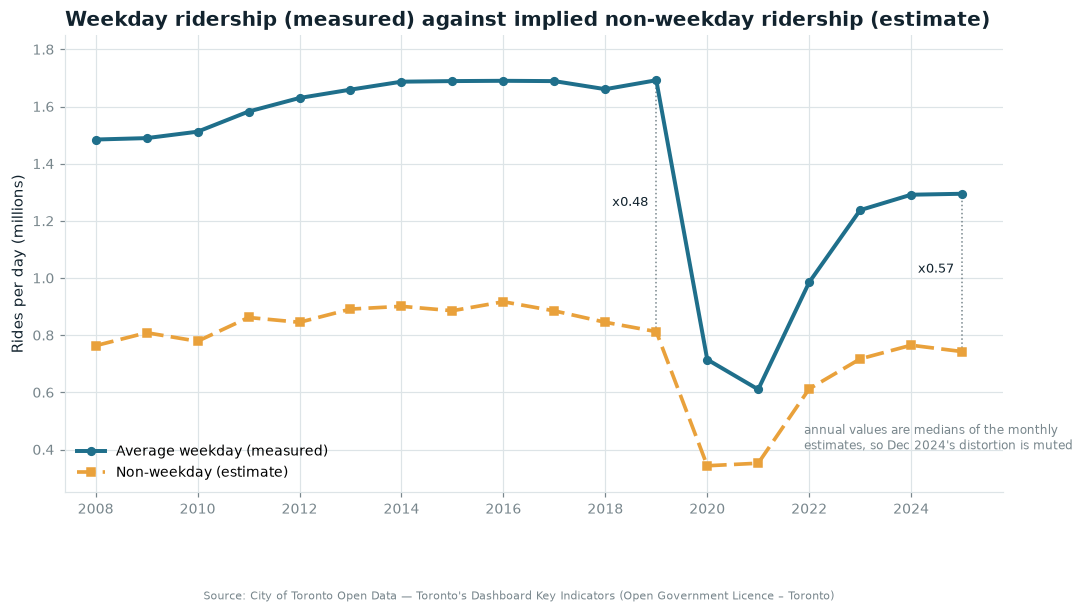

consistency: 4-week periods imply 817,438 rides/day, 5-week 819,200 (+0.22%) - coherent with the assumed calendar, not proof of it
estimate, non-weekday/weekday ratio: 2008 0.514 | 2016 0.543 | 2019 0.480 | 2025 0.574
Dec 2024 implied 1,421,300 rides/day vs 764,938 for 2024 as a whole - that month's weekday figure looks understated


In [19]:
# --- Section 6.1 - ESTIMATE of non-weekday ridership from the weekday series ---
wkmix = monthly.copy()          # period_weeks comes from the assumed 4-4-5 table in 1.3
wkmix["weekday_count"] = wkmix["period_weeks"] * 5
wkmix["weekend_count"] = wkmix["period_weeks"] * 2
wkmix["weekend_rides"] = wkmix["ridership"] - wkmix["weekday_count"] * wkmix["avg_weekday"]
wkmix["weekend_per_day"] = wkmix["weekend_rides"] / wkmix["weekend_count"]

complete_years = [y for y in wkmix.index.year.unique() if y != PARTIAL_YEAR]
by_year = pd.DataFrame({
    "weekday": wkmix["avg_weekday"].groupby(wkmix.index.year).mean(),
    "weekend": wkmix["weekend_per_day"].groupby(wkmix.index.year).median(),
}).loc[complete_years]          # 2026 is partial, so it is left out of the level chart
by_year["ratio"] = by_year["weekend"] / by_year["weekday"]

# Jan-Sep in every year, so the partial final year can be indexed against a matched baseline
ytd_only = wkmix[wkmix.index.month <= 9]
by_year_ytd = pd.DataFrame({
    "weekday": ytd_only["avg_weekday"].groupby(ytd_only.index.year).mean(),
    "weekend": ytd_only["weekend_per_day"].groupby(ytd_only.index.year).median(),
})

fig, ax = plt.subplots(figsize=(11, 5.4))
ax.plot(by_year.index, by_year["weekday"] / 1e6, color=BLUE, lw=2.6, marker="o", ms=5,
        zorder=4, label="Average weekday (measured)")
ax.plot(by_year.index, by_year["weekend"] / 1e6, color=AMBER, lw=2.4, marker="s", ms=5,
        ls=(0, (5, 2)), zorder=4, label="Non-weekday (estimate)")

for year in (2019, 2025):
    ax.vlines(year, by_year.loc[year, "weekend"] / 1e6, by_year.loc[year, "weekday"] / 1e6,
              color=GREY, lw=1, ls=":", zorder=2)
    ax.text(year - 0.16, (by_year.loc[year, "weekday"] + by_year.loc[year, "weekend"]) / 2e6,
            f"x{by_year.loc[year, 'ratio']:.2f}", fontsize=8.5, color=INK, ha="right")

ax.text(2021.9, 0.44, "annual values are medians of the monthly\n"
        "estimates, so Dec 2024's distortion is muted",
        fontsize=8, color=GREY, ha="left", va="center", zorder=6)

ax.set_xlim(2007.4, 2025.8)
ax.set_ylim(0.25, 1.85)
ax.set_xticks(range(2008, 2026, 2))
ax.set_ylabel("Rides per day (millions)")
ax.set_title("Weekday ridership (measured) against implied non-weekday ridership (estimate)")
ax.legend(loc="lower left", fontsize=9)

png = save_fig(fig, "06_weekday_vs_weekend")
plt.show()

# --- checks ---
assert (wkmix["weekend_per_day"] > 0).all(), "an implied estimate went negative"
assert (wkmix["weekend_per_day"] < wkmix["avg_weekday"]).mean() > 0.95, "implausible estimates"
# consistency check: both period lengths give the same implied non-weekday ridership.
# This shows the assumed calendar is internally coherent - it does NOT show it was TTC's real one.
med4 = wkmix.loc[wkmix["period_weeks"] == 4, "weekend_per_day"].median()
med5 = wkmix.loc[wkmix["period_weeks"] == 5, "weekend_per_day"].median()
assert abs(med5 / med4 - 1) < 0.01, (med4, med5)
assert abs(by_year.loc[2019, "ratio"] - 0.48) < 0.01 and abs(by_year.loc[2025, "ratio"] - 0.57) < 0.01
assert by_year.loc[2025, "ratio"] > by_year.loc[2019, "ratio"]
assert PARTIAL_YEAR not in by_year.index and PARTIAL_YEAR in by_year_ytd.index
assert png.exists() and png.stat().st_size > 35_000, png
print(f"consistency: 4-week periods imply {med4:,.0f} rides/day, 5-week {med5:,.0f} "
      f"({(med5 / med4 - 1) * 100:+.2f}%) - coherent with the assumed calendar, not proof of it")
print(f"estimate, non-weekday/weekday ratio: 2008 {by_year.loc[2008, 'ratio']:.3f} | "
      f"2016 {by_year.loc[2016, 'ratio']:.3f} | 2019 {by_year.loc[2019, 'ratio']:.3f} | "
      f"2025 {by_year.loc[2025, 'ratio']:.3f}")
print(f"Dec 2024 implied {wkmix.loc['2024-12-01', 'weekend_per_day']:,.0f} rides/day "
      f"vs {wkmix.loc['2024', 'weekend_per_day'].median():,.0f} for 2024 as a whole - "
      f"that month's weekday figure looks understated")

### 6.2 Weekday recovery is weaker than non-weekday recovery

Indexing both series to 2019 answers the question the peak/non-peak measures cannot. In 2025,
weekday ridership sits at **77%** of 2019 while estimated non-weekday ridership sits at **91%** —
a gap of about 14 points that has held since 2022.

Two caveats, both load-bearing:

- the non-weekday figure is an **estimate** resting on the assumed reporting calendar, so if that
  assumption is wrong, so is the 91%;
- weekday ridership is not the same thing as commuting. A weekday trip can be education, shopping,
  an appointment or leisure as easily as a trip to work. This data has no trip-purpose field, so
  "commuting has not returned" is a **plausible explanation, not a finding** — what the data shows
  is that weekday travel is recovering more slowly than non-weekday travel.

All years here, including the 2019 baseline, cover **January to September**, so the partial final
year is compared like for like.


saved visualizations/06_weekend_recovery.png  (96 KB)


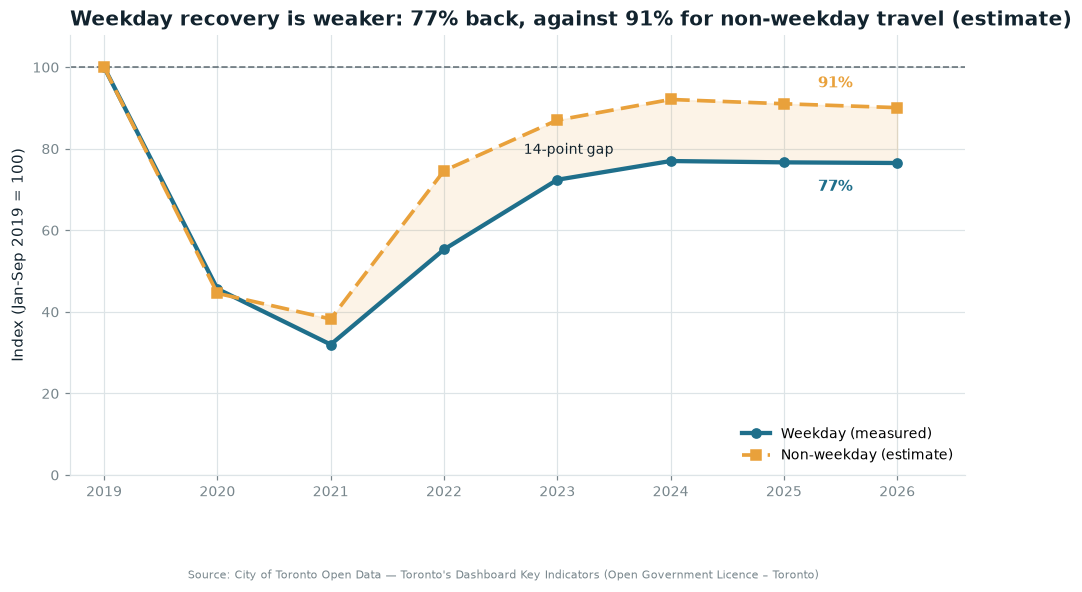

2025 vs Jan-Sep 2019: weekday 76.7% (measured) | non-weekday 91.0% (estimate) | gap 14.4 pts
2026 Jan-Sep: weekday 76.5% | non-weekday 90.1%
baseline check: Jan-Sep 2019 weekday mean 1,681,111 vs full-year 1,691,833 - matched months matter for the partial year


In [20]:
# --- Section 6.2 - weekday vs non-weekday recovery, indexed to a matched Jan-Sep 2019 ---
recovery = pd.DataFrame({
    "weekday": by_year_ytd["weekday"] / by_year_ytd.loc[2019, "weekday"] * 100,
    "weekend": by_year_ytd["weekend"] / by_year_ytd.loc[2019, "weekend"] * 100,
}).loc[2019:]

fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.plot(recovery.index, recovery["weekday"], color=BLUE, lw=2.8, marker="o", ms=6,
        zorder=4, label="Weekday (measured)")
ax.plot(recovery.index, recovery["weekend"], color=AMBER, lw=2.4, marker="s", ms=6,
        ls=(0, (5, 2)), zorder=4, label="Non-weekday (estimate)")
ax.axhline(100, color=INK, lw=1.1, ls="--", alpha=0.6, zorder=2)

for col, color, dy in (("weekend", AMBER, 5), ("weekday", BLUE, -6)):
    value = recovery.loc[2025, col]
    ax.annotate(f"{value:.0f}%", xy=(2025, value), xytext=(2025.3, value + dy),
                fontsize=10, color=color, weight="bold", va="center", ha="left")

ax.fill_between(recovery.index, recovery["weekday"], recovery["weekend"],
                color=AMBER, alpha=0.12, zorder=1)
ax.annotate(f"{recovery.loc[2025, 'weekend'] - recovery.loc[2025, 'weekday']:.0f}-point gap",
            xy=(2023.1, (recovery.loc[2023, "weekday"] + recovery.loc[2023, "weekend"]) / 2),
            fontsize=9, color=INK, ha="center", va="center", zorder=5)

ax.set_xlim(2018.7, 2026.6)
ax.set_ylim(0, 108)
ax.set_xticks(range(2019, 2027))
ax.set_ylabel("Index (Jan-Sep 2019 = 100)")
ax.set_title("Weekday recovery is weaker: 77% back, against 91% for non-weekday travel (estimate)")
ax.legend(loc="lower right", fontsize=9)

png = save_fig(fig, "06_weekend_recovery")
plt.show()

# --- checks ---
assert np.isclose(recovery.loc[2019], 100).all()
# the baseline must be matched months, not a full year - this is the fix for the 2026 comparison
full_year_2019 = wkmix["avg_weekday"].groupby(wkmix.index.year).mean().loc[2019]
assert not np.isclose(by_year_ytd.loc[2019, "weekday"], full_year_2019)
assert 2019 in by_year_ytd.index and PARTIAL_YEAR in by_year_ytd.index
assert recovery.loc[2025, "weekend"] > recovery.loc[2025, "weekday"]
assert abs(recovery.loc[2025, "weekday"] - 76.7) < 1.0, recovery.loc[2025, "weekday"]
assert abs(recovery.loc[2025, "weekend"] - 91.0) < 1.0, recovery.loc[2025, "weekend"]
assert (recovery.loc[2022:, "weekend"] > recovery.loc[2022:, "weekday"]).all()
assert png.exists() and png.stat().st_size > 30_000, png
print(f"2025 vs Jan-Sep 2019: weekday {recovery.loc[2025, 'weekday']:.1f}% (measured) | "
      f"non-weekday {recovery.loc[2025, 'weekend']:.1f}% (estimate) | "
      f"gap {recovery.loc[2025, 'weekend'] - recovery.loc[2025, 'weekday']:.1f} pts")
print(f"2026 Jan-Sep: weekday {recovery.loc[2026, 'weekday']:.1f}% | "
      f"non-weekday {recovery.loc[2026, 'weekend']:.1f}%")
print(f"baseline check: Jan-Sep 2019 weekday mean {by_year_ytd.loc[2019, 'weekday']:,.0f} "
      f"vs full-year {full_year_2019:,.0f} - matched months matter for the partial year")

## 🧭 Section 7 — Summary

Four panels, one per finding: the two-decade arc, the seasonal shape and how it changed, the
recovery that stalled, and the peak-hour share that stops being readable after 2021.

The four are the same story seen from different angles — ridership grew to a 2016 peak, the
pre-pandemic years were already flat, the collapse removed the equivalent of the peak year's
ridership twice over, and the recovery has stalled near 78% of 2019 with weekday travel the weaker
half. The one thing this data cannot tell you is *why*: it has no trip-purpose field.


saved visualizations/07_dashboard.png  (252 KB)


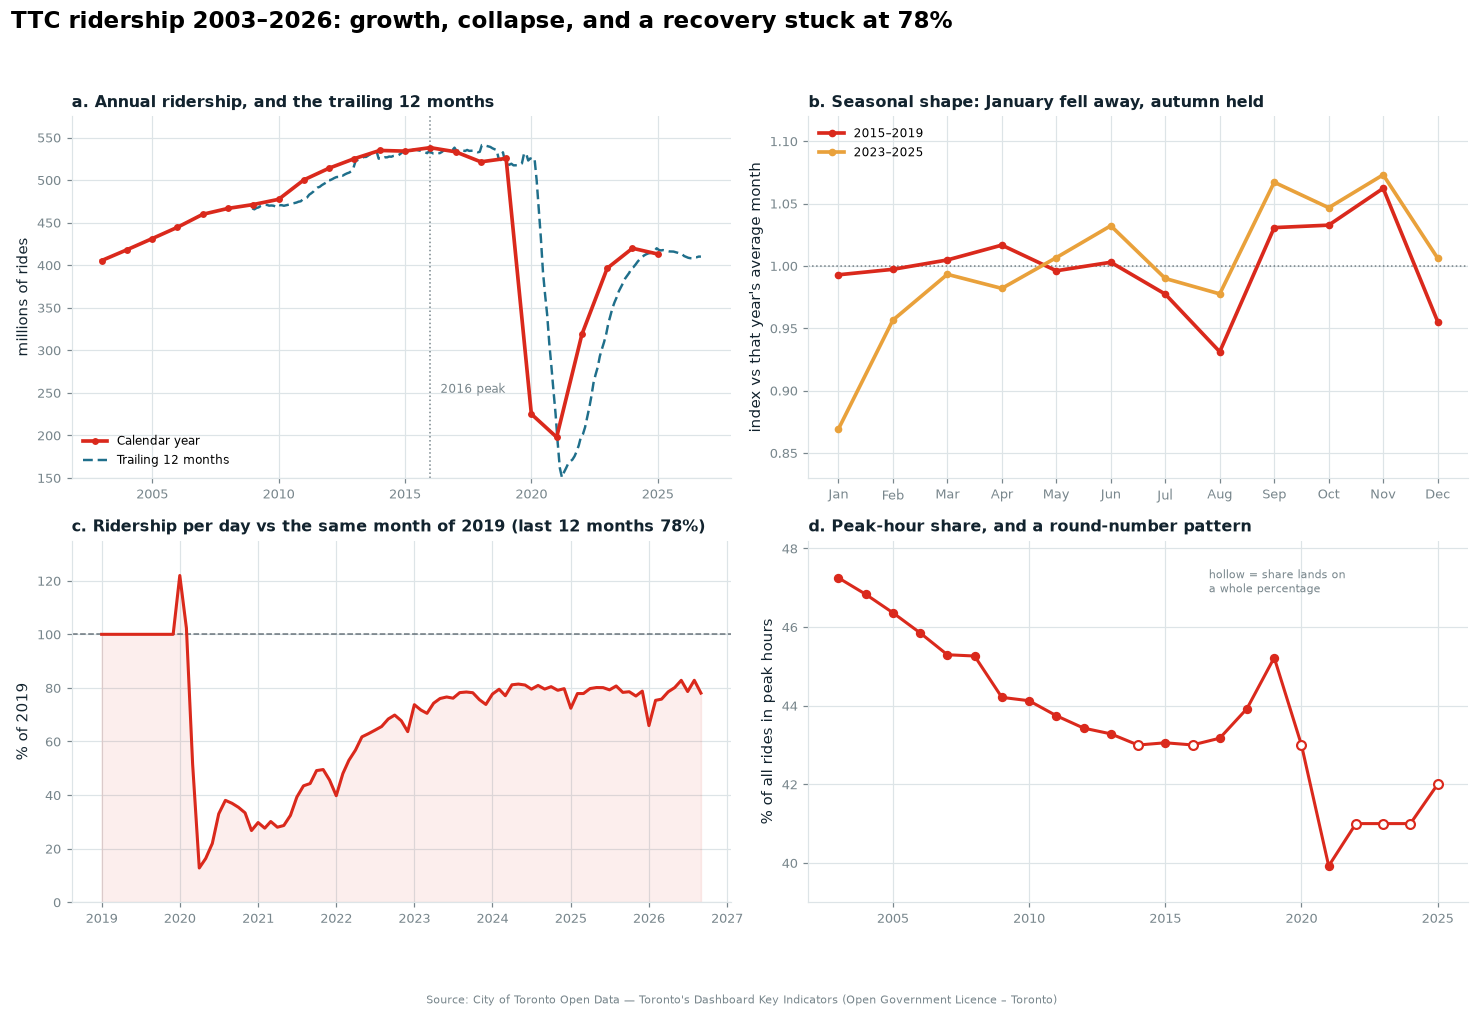

dashboard: 4 panels, 252 KB


In [21]:
# --- Section 7.1 - summary dashboard ---
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.6))
fig.suptitle("TTC ridership 2003\u20132026: growth, collapse, and a recovery stuck at 78%",
             fontsize=15, weight="bold", x=0.008, ha="left", y=0.985)

# (a) the long arc
ax = axes[0, 0]
ax.plot(annual.index, annual["total"] / 1e6, color=RED, lw=2.4, marker="o", ms=3.5,
        zorder=3, label="Calendar year")
t12 = monthly["trailing_12m"].dropna() / 1e6
ax.plot(t12.index.year + (t12.index.month - 0.5) / 12, t12, color=BLUE, lw=1.6,
        ls=(0, (4, 2)), zorder=2, label="Trailing 12 months")
ax.axvline(2016, color=GREY, lw=1, ls=":", zorder=1)
ax.text(2016.4, 250, "2016 peak", fontsize=8, color=GREY)
ax.set_title("a. Annual ridership, and the trailing 12 months", fontsize=10.5)
ax.set_ylabel("millions of rides")
ax.set_ylim(150, 575)
ax.legend(loc="lower left", fontsize=8)

# (b) seasonality, before vs after
ax = axes[0, 1]
for label, (lo, hi), color in (("2015\u20132019", (2015, 2019), RED),
                               ("2023\u20132025", (2023, 2025), AMBER)):
    series = seasonal.loc[lo:hi].mean()
    ax.plot(np.arange(12), series.to_numpy(), color=color, lw=2.4, marker="o", ms=4,
            label=label, zorder=3)
ax.axhline(1.0, color=INK, lw=1, ls=":", alpha=0.55, zorder=2)
ax.set_xticks(np.arange(12), MONTH_ORDER, fontsize=8)
ax.set_title("b. Seasonal shape: January fell away, autumn held", fontsize=10.5)
ax.set_ylabel("index vs that year's average month")
ax.set_ylim(0.83, 1.12)
ax.legend(loc="upper left", fontsize=8)

# (c) recovery index
ax = axes[1, 0]
ax.plot(recent.index, recent.to_numpy(), color=RED, lw=2, zorder=3)
ax.axhline(100, color=INK, lw=1, ls="--", alpha=0.6, zorder=2)
ax.fill_between(recent.index, 0, recent.to_numpy(), color=RED, alpha=0.08, zorder=1)
ax.set_title(f"c. Ridership per day vs the same month of 2019 "
             f"(last 12 months {last12.mean():.0f}%)", fontsize=10.5)
ax.set_ylabel("% of 2019")
ax.set_ylim(0, 135)

# (d) peak-hour share, with the round-number years called out
ax = axes[1, 1]
ax.plot(share.index, share.to_numpy(), color=RED, lw=2, zorder=3)
ax.scatter(share.index[other_years], share[other_years], s=26, color=RED, zorder=4)
ax.scatter(share.index[round_number], share[round_number], s=34, facecolor="white",
           edgecolor=RED, linewidth=1.4, zorder=5)
ax.text(2016.6, 47.5, "hollow = share lands on\na whole percentage",
        fontsize=7.5, color=GREY, ha="left", va="top")
ax.set_title("d. Peak-hour share, and a round-number pattern", fontsize=10.5)
ax.set_ylabel("% of all rides in peak hours")
ax.set_ylim(39, 48.2)

for ax in axes.flat:
    ax.tick_params(labelsize=8.5)

fig.tight_layout(rect=(0, 0, 1, 0.955))
png = save_fig(fig, "07_dashboard")
plt.show()

# --- checks ---
assert len(fig.axes) == 4
assert png.exists() and png.stat().st_size > 90_000, png
print(f"dashboard: 4 panels, {png.stat().st_size / 1024:.0f} KB")

### 7.2 What the data says

| # | Finding | Evidence | Confidence |
|---|---|---|---|
| 1 | **Ridership peaked in 2016**, not 2019 | 538.1M in 2016; 2019 was already −2.3% below it after three down years in four (§2.2) | measured |
| 2 | **Growth was steady, then it wasn't** | +2.20%/yr compound 2003–2016, then a four-year plateau (§2.4) | measured |
| 3 | **The collapse removed 63% of peak ridership** | 538.1M (2016) → 197.8M (2021); the worst month fell to 12.8% of 2019 (§4.1) | measured |
| 4 | **Recovery stalled near 78% and is slipping** | Jan–Sep index: 79.9% (2024) → 78.7% (2025) → 77.9% (2026) (§4.3) | measured, per-day basis |
| 5 | **Weekday travel recovered less than non-weekday travel** | 2025 vs Jan–Sep 2019: weekday **77%**, non-weekday **91%** (§6.2) | weekday measured; non-weekday **estimated** |
| 6 | **Winter carries most of the loss** | January is the weakest month (index 0.87) *and* the weakest recovery (72%), and it is falling (§3.2, §4.2) | per-day basis, assumed calendar |
| 7 | **The peak-hour split is unusable after 2021** | the published share lands on a whole percentage in 7 of 23 years, including 2022–2025 (§5.1) | caution flag, not a measurement |
| 8 | **The reporting calendar is inferred, not documented** | no upstream metadata defines a period; the 4‑4‑5 table is an assumption validated only for internal consistency (§1.3) | assumption |

What is *not* established here: why ridership behaviour changed. This dataset has no trip purpose, so
"commuting has not returned" is a plausible reading of the weekday/non-weekday gap, not a result.

### 7.3 What this data cannot answer

- **Trip purpose** — no field distinguishes commuting from education, shopping or leisure, so the
  weekday shortfall cannot be attributed to commuting.
- **No route, line or station detail** — "which line recovered fastest" is unanswerable here.
- **No fare revenue** — the upstream dataset publishes `TTC Ridership Revenues` separately.
- **No daily or hourly ridership** — peak-hour *share* is annual, so intraday shape is invisible.
- **No measured peak/non-peak split after 2021** — see §5.1.
- **No documented reporting calendar** — every per-day figure in this notebook depends on an
  inferred 4‑4‑5 assumption (§1.3).
- **2026 is partial** (Jan–Sep), so every 2026 statement is year-to-date and per-reporting-day.

### 7.4 The one-line version

TTC ridership grew 33% to a 2016 peak, lost nearly two thirds of it, and has recovered to roughly
**78% of its pre-pandemic level** — with the shortfall concentrated in weekday and winter travel,
trip purpose unknown, and no sign of renewed growth since 2024.
